## Cell 1: imports

In [1]:
import os, heapq, itertools, time, json
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import gymnasium as gym
from gymnasium import spaces
from sb3_contrib import MaskablePPO

## Cell 2: problem, grid, exact solution, boundary data

In [2]:
# ── Problem settings: change PROBLEM, everything below follows ──
#   "walls"         : u0 = sin(pi x) + 0.5 sin(2 pi x), u = 0 at both walls, alpha = 0.1   (notebook 12, for comparison)
#   "inflow_smooth" : u0 = 1 + 0.8 sin(2 pi x / 1.5), time-dependent Dirichlet data from the exact solution, alpha = 0.1
#   "inflow_front"  : same, alpha = 0.01: a front forms and leaves (t ~ 0.25-0.35); a second one enters through the left wall (t ~ 0.7)
PROBLEM = "inflow_smooth"
alpha, T = {"walls": (0.1, 0.5), "inflow_smooth": (0.1, 0.5), "inflow_front": (0.01, 1.1)}[PROBLEM]

# ── PDE:  u_t + a(u) u_x = alpha u_xx  on [0, 1] ──
a = lambda u: u                                # advection speed: Burgers
if PROBLEM == "walls":
    u0 = lambda x: np.sin(np.pi * x) + 0.5 * np.sin(2 * np.pi * x)
    F0 = lambda x: (1 - np.cos(np.pi * x)) / np.pi + (1 - np.cos(2 * np.pi * x)) / (4 * np.pi)   # integral of u0 from 0
    A_MAX = 1.5                                # bound on |u| (the IC peaks at about 1.26)
else:
    C_BG, A_W, L_W = 1.0, 0.8, 1.5             # background speed, amplitude, wavelength: u stays in [0.2, 1.8] > 0
    u0 = lambda x: C_BG + A_W * np.sin(2 * np.pi * x / L_W)        # (wavelength != 1, so the two walls see different data)
    F0 = lambda x: C_BG * x + A_W * L_W * (1 - np.cos(2 * np.pi * x / L_W)) / (2 * np.pi)
    A_MAX = C_BG + A_W

# ── Grid ──
# explicit advection + diffusion (LW, FD-3) is stable for 2r + nu^2 <= 1, r = alpha dt/dx^2, nu = A_MAX dt/dx; 0.9 for margin
nx = 50
dx = 1.0 / (nx - 1)
_c2, _c1 = (A_MAX / dx)**2, 2 * alpha / dx**2
nt = int(np.ceil(T / ((-_c1 + np.sqrt(_c1**2 + 4 * _c2 * 0.9)) / (2 * _c2)))) + 1
dt = T / (nt - 1)
x_grid = np.arange(nx) * dx

# ── Exact solution (Hopf-Cole), as a weighted average so it stays accurate for small alpha ──
#    u(x, t) = sum (x - y)/t W / sum W,   W = exp(-F0(y)/(2 alpha) - (x - y)^2 / (4 alpha t)),   y on a uniform grid.
#    "walls": F0 mirrored about every wall (even, period 2) -> phi_x = 0 -> u = 0 at x = 0 and 1.
#    inflow : the whole line, no mirrors; the weight peaks near the foot of the characteristic, y ~ x - u t,
#             so the y range reaches A_MAX * T to the left. Both cover 8 kernel widths. Exponents shifted by their max.
_s = 8 * np.sqrt(2 * alpha * T)
if PROBLEM == "walls":
    _lo, _hi = -np.ceil(_s), 1 + np.ceil(_s)
    _Y  = np.linspace(_lo, _hi, int(round((_hi - _lo) * 10000)) + 1)
    _yf = np.mod(_Y, 2.0)
    _FY = F0(np.where(_yf > 1, 2 - _yf, _yf)) / (2 * alpha)
else:
    _lo, _hi = -A_MAX * T - _s, 1 + _s
    _Y  = np.linspace(_lo, _hi, int(round((_hi - _lo) * 10000)) + 1)
    _FY = F0(_Y) / (2 * alpha)

def u_true(x, t):
    x = np.atleast_1d(np.asarray(x, dtype=float))
    if t <= 0:
        return u0(x)
    out = np.empty(len(x))
    for i in range(0, len(x), 50):                             # chunks of x, to keep memory small
        xs = x[i:i + 50, None]
        E  = -_FY - (xs - _Y)**2 / (4 * alpha * t)
        W  = np.exp(E - E.max(axis=1, keepdims=True))
        out[i:i + 50] = ((xs - _Y) / t * W).sum(1) / W.sum(1)
    return out

# exact values on the grid, one time level at a time when first needed (u_true ONLY for checks, reports, and wall data)
_U_rows = {}
def U_row(it):
    if it not in _U_rows:
        _U_rows[it] = u_true(x_grid, it * dt)
    return _U_rows[it]
Ug = lambda q: U_row(q[1])[q[0]]

# ── Boundary data: u at x = 0 and x = 1 as functions of t (given data, like the IC) ──
# on the grid's time levels it is exact (U_row); between levels (refined classical schemes) a cubic spline through a fine table
from scipy.interpolate import CubicSpline
_tb = np.linspace(0.0, T, 2001)
_gb = np.array([u_true([0.0, 1.0], t) for t in _tb])            # (time, [left, right])
_gs = CubicSpline(_tb, _gb)                                     # cubic in t: accurate enough for high-order schemes too
g_left  = lambda t: float(_gs(t)[0])
g_right = lambda t: float(_gs(t)[1])

r_, nu_ = alpha * dt / dx**2, A_MAX * dt / dx
print(f"{PROBLEM}: alpha = {alpha}, T = {T} | nx = {nx}, nt = {nt}, dx = {dx:.5f}, dt = {dt:.3e} | "
      f"r = {r_:.2f}, nu_max = {nu_:.2f}, 2r + nu^2 = {2 * r_ + nu_**2:.2f}")

inflow_smooth: alpha = 0.1, T = 0.5 | nx = 50, nt = 276, dx = 0.02041, dt = 1.818e-03 | r = 0.44, nu_max = 0.16, 2r + nu^2 = 0.90


 ## Cell 3: Taylor predictor
 

In [3]:
# ── Taylor predictor: 3 rows (value, u_x, u_xx) with u_t = alpha u_xx - a u_x substituted ──
COND_MAX, W_MAX = 1e4, 2.0
def solve_weights_many(DX, DT, a_loc):
    """Min-norm weights for M stencils at once: DX, DT of shape (M, n) = neighbour offsets, a_loc = local speed.
    Returns W (M, n) and ok (M,): admissible = rank 3, cond <= COND_MAX and ||w||_1 <= W_MAX."""
    xi = DX - a_loc * DT                                              # offset in the moving frame
    h  = np.maximum(np.abs(DX).max(1), np.sqrt(alpha * np.abs(DT).max(1)))[:, None]
    A  = np.stack([np.ones_like(DX), xi / h, (0.5 * xi**2 + alpha * DT) / h**2], axis=1)   # (M, 3, n)
    s  = np.linalg.svd(A, compute_uv=False)                           # singular values, largest first
    ok = (s[:, -1] > s[:, 0] * DX.shape[1] * np.finfo(float).eps) & (s[:, 0] <= COND_MAX * s[:, -1])
    W  = np.linalg.pinv(A) @ np.array([1.0, 0.0, 0.0])
    return W, ok & (np.abs(W).sum(1) <= W_MAX)

def solve_weights(dxs, dts, a_loc):
    """One stencil: weights, or None if not admissible."""
    W, ok = solve_weights_many(dxs[None], dts[None], a_loc)
    return W[0] if ok[0] else None

## Cell 4: score

In [4]:
# ── Local error estimate (score): the stencil's error on the local Taylor polynomial of u around p ──
# PDE-specific part: Taylor coefficients with every time derivative replaced using Burgers, u_t = alpha u_xx - u u_x
def taylor_coeffs(d):
    """d = (u, u_x, u_xx, u_xxx, u_xxxx) at p. Returns {(i, j): (d/dx)^i (d/dt)^j u / (i! j!)} for weight i + 2j <= 4."""
    u, u1, u2, u3, u4 = d
    ut   = alpha * u2 - u * u1
    uxt  = alpha * u3 - u * u2 - u1**2                                     # Burgers term: - u_x^2
    uxxt = alpha * u4 - u * u3 - 3 * u1 * u2                               # Burgers term: - 3 u_x u_xx
    utt  = alpha**2 * u4 - 2 * alpha * u * u3 + u**2 * u2 + 2 * u1 * (u * u1 - 2 * alpha * u2)   # Burgers term: 2 u_x (...)
    return {(1, 0): u1, (2, 0): u2 / 2, (3, 0): u3 / 6, (4, 0): u4 / 24,
            (0, 1): ut, (1, 1): uxt, (2, 1): uxxt / 2, (0, 2): utt / 2}

def score(DX, DT, w, d):
    """|sum_q w_q P(dx_q, dt_q)|, P = Taylor polynomial of u around p (without u_p). One stencil (n,) or M stencils (M, n)."""
    P = sum(c * DX**i * DT**j for (i, j), c in taylor_coeffs(d).items())
    return np.abs((w * P).sum(-1))


## Cell 5: coarse guess


In [5]:
# ── Rough guess of u and its x-derivatives, used ONLY to build the map (speed, weights, score, influence) ──
# Lax-Wendroff on a grid K_COARSE times coarser, from the initial condition to T, with the same boundary data; computed once.
K_COARSE = {"walls": 5, "inflow_smooth": 3, "inflow_front": 2}[PROBLEM]       # the front needs a finer guess
from scipy.interpolate import make_interp_spline
xc  = np.linspace(0.0, 1.0, (nx - 1) // K_COARSE + 1)
hc  = xc[1] - xc[0]
_c2, _c1 = (A_MAX / hc)**2, 2 * alpha / hc**2                                 # same stability rule as the main grid
tau = T / int(np.ceil(T / ((-_c1 + np.sqrt(_c1**2 + 4 * _c2 * 0.9)) / (2 * _c2))))
tc  = np.arange(0.0, T + tau / 2, tau)
Uc  = [u0(xc)]
for j in range(1, len(tc)):
    u, ui = Uc[-1], Uc[-1][1:-1]
    r, nu = alpha * tau / hc**2, a(ui) * tau / hc
    n = u.copy()
    n[1:-1] = ui + (r + nu**2 / 2) * (u[2:] - 2 * ui + u[:-2]) - nu / 2 * (u[2:] - u[:-2])
    n[0], n[-1] = g_left(tc[j]), g_right(tc[j])                               # boundary data
    Uc.append(n)
G_COARSE = len(xc) * len(tc)                                                  # cost of the guess (grid points)

# ── Smooth fit in x at each coarse time: a quintic spline through the coarse values, differentiated exactly ──
Dc = np.zeros((5, len(tc), nx))                                               # (derivative order, coarse time, our x)
for j, u in enumerate(Uc):
    sp = make_interp_spline(xc, u, k=5)
    for k in range(5):
        Dc[k, j] = sp.derivative(k)(x_grid) if k else sp(x_grid)

# ── Linear in time onto our grid: GUESS[k, it, ix] = k-th x-derivative of the guess at grid point (ix, it) ──
tg = np.arange(nt) * dt
jj = np.minimum((tg // tau).astype(int), len(tc) - 2)
f  = ((tg - tc[jj]) / tau)[None, :, None]
GUESS = (1 - f) * Dc[:, jj] + f * Dc[:, jj + 1]
guess_derivs = lambda q: GUESS[:, q[1], q[0]]                                 # (u, u_x, u_xx, u_xxx, u_xxxx) at q

## Cell 6: the map (with the live-speed forward pass)

In [6]:
# ── Known data: the initial condition and the walls are given, not computed ──
# their values are the exact solution there: u0 at t = 0, the boundary data g_left / g_right on the walls
is_known    = lambda q: q[1] == 0 or q[0] in (0, nx - 1)
known_value = Ug

# ── Speed at p for its weights: from the guess, rounded to A_STEP so weights can be cached ──
A_STEP  = 0.02
a_build = lambda p: A_STEP * round(a(guess_derivs(p)[0]) / A_STEP)

_w_cache = {}
def weights(p, nbs):
    """Taylor weights of p's neighbours nbs (grid points), with p's guessed speed; None if not admissible.
    Cached by (shape, speed). Solved with the neighbours sorted (latest level first, then left to right), so the
    result never depends on the order the neighbours were picked in."""
    order = sorted(range(len(nbs)), key=lambda i: (-nbs[i][1], nbs[i][0]))
    offs  = tuple((nbs[i][0] - p[0], nbs[i][1] - p[1]) for i in order)
    key   = (offs, a_build(p))
    if key not in _w_cache:
        _w_cache[key] = solve_weights(np.array([o[0] for o in offs]) * dx, np.array([o[1] for o in offs]) * dt, key[1])
    if _w_cache[key] is None:
        return None
    w = np.empty(len(nbs)); w[order] = _w_cache[key]                  # back to the order of nbs
    return w

def point_score(p, nbs, w):
    """Estimated local error of p's stencil, with the guessed derivatives at p."""
    return score(np.array([q[0] - p[0] for q in nbs]) * dx, np.array([q[1] - p[1] for q in nbs]) * dt, w, guess_derivs(p))

# ── The map, built backward from z* ──
# Points wait in `pending` and are expanded LATEST t first: every point that can use p is later
# than p, so it is already expanded and p's influence beta_p is complete when p is expanded.
def start_map(z_star):
    return {"z_star": z_star, "pending": [(-z_star[1], z_star[0])], "beta": {z_star: 1.0}, "stencil": {}}

def next_point(m):
    it, ix = m["pending"][0]
    return (ix, -it)

def expand(m, nbs):
    """Give the next point the stencil nbs and pass its influence down: beta_q += beta_p * w_q."""
    it, ix = heapq.heappop(m["pending"])
    p = (ix, -it)
    w = weights(p, nbs)
    m["stencil"][p] = (nbs, w)
    for q, wq in zip(nbs, w):
        if is_known(q):
            continue                                   # IC or wall: exact, the map stops here
        if q not in m["beta"]:
            m["beta"][q] = 0.0
            heapq.heappush(m["pending"], (-q[1], q[0]))
        m["beta"][q] += m["beta"][p] * wq
    return p, w

def build_map(z_star, choose):
    """Whole map; choose(m, p) returns the neighbours of p."""
    m = start_map(z_star)
    while m["pending"]:
        expand(m, choose(m, next_point(m)))
    return m

# ── Forward pass: values bottom-up, from the IC and walls to z* ──
# The map fixes the neighbours (chosen with the guessed speed). Each point then re-solves its weights with the speed
# of its own computed value (picard steps; 0 = keep the map's weights), so the guessed speed never enters the values.
# The weights actually used are kept in m["w_used"] (report needs them).
def evaluate(m, picard=1):
    u_hat, m["w_used"] = {}, {}
    value = lambda q: known_value(q) if is_known(q) else u_hat[q]
    for p in sorted(m["stencil"], key=lambda p: p[1]):          # increasing t: neighbours are ready
        nbs, w = m["stencil"][p]
        v = np.array([value(q) for q in nbs])
        DX, DT = np.array([q[0] - p[0] for q in nbs]) * dx, np.array([q[1] - p[1] for q in nbs]) * dt
        for _ in range(picard):
            w_new = solve_weights(DX, DT, a(w @ v))             # speed from the value just computed
            if w_new is None:                                   # not admissible: keep the last weights
                break
            w = w_new
        m["w_used"][p], u_hat[p] = w, w @ v
    return u_hat

# ── The Lax-Wendroff rule: every point takes 3 points one level down (the reference) ──
lw = lambda m, p: [(p[0] - 1, p[1] - 1), (p[0], p[1] - 1), (p[0] + 1, p[1] - 1)]

## Cell 7: window, admissible stencils, mask, lowest score, report


In [7]:
# ── The window: candidate neighbour cells below p ──
R_X, K_T = 3, 3                       # |dix| <= 3 cells, 1 to 3 levels down
WINDOW  = [(dix, dit) for dit in range(-1, -K_T - 1, -1) for dix in range(-R_X, R_X + 1)]
N_CELLS = len(WINDOW)
N_NB    = 5                           # neighbours per stencil
TERMS   = list(taylor_coeffs((0.0,) * 5))                             # the (i, j) Taylor terms of the score

def place(p, k):
    """Grid point of window cell k seen from p. Past a wall or below t = 0 -> moved onto it."""
    return (min(max(p[0] + WINDOW[k][0], 0), nx - 1), max(p[1] + WINDOW[k][1], 0))

# ── Every admissible stencil at p ──
# Cached by p's local situation and guessed speed: the stencils, which cells they use, and their moments
# sum_q w_q dx^i dt^j for each Taylor term. The score at p is then |moments @ Taylor coefficients at p|.
_sets_cache = {}
def admissible(p):
    """(stencils as tuples of cells, cell-usage matrix, scores at p). Cells that land on the same point count once."""
    key = (tuple((place(p, k)[0] - p[0], place(p, k)[1] - p[1]) for k in range(N_CELLS)), a_build(p))
    if key not in _sets_cache:
        cells, seen = [], set()
        for k in range(N_CELLS):
            if place(p, k) not in seen:
                seen.add(place(p, k)); cells.append(k)
        sets = list(itertools.combinations(cells, min(N_NB, len(cells))))
        off  = np.array([[(place(p, k)[0] - p[0], place(p, k)[1] - p[1]) for k in s] for s in sets])   # (M, n, 2)
        DX, DT = off[..., 0] * dx, off[..., 1] * dt
        W, ok  = solve_weights_many(DX, DT, a_build(p))                # all candidate stencils in one solve
        sets   = [s for s, o in zip(sets, ok) if o]
        mom    = np.stack([(W[ok] * DX[ok]**i * DT[ok]**j).sum(1) for i, j in TERMS], axis=1)
        uses   = np.zeros((len(sets), N_CELLS), dtype=bool)
        for i, s in enumerate(sets):
            uses[i, list(s)] = True
        _sets_cache[key] = (sets, uses, mom)
    sets, uses, mom = _sets_cache[key]
    c = taylor_coeffs(guess_derivs(p))
    return sets, uses, np.abs(mom @ np.array([c[t] for t in TERMS]))

def pick_mask(p, picks):
    """Cell k may be picked next if some admissible stencil contains the picks so far plus k."""
    _, uses, _ = admissible(p)
    ok = uses[:, picks].all(axis=1) if picks else np.ones(len(uses), dtype=bool)
    mask = uses[ok].any(axis=0)
    mask[picks] = False
    return mask

# ── A first rule without RL: every point takes its lowest-score stencil ──
def lowest_score(m, p):
    sets, _, sc = admissible(p)
    return [place(p, k) for k in sets[int(np.argmin(sc))]]

# ── Report of a finished map: points, true error at z*, exact bound sum |beta delta| (u_true ONLY for reporting) ──
# with the weights the forward pass actually used (live speed); beta is recomputed with them, so e(z*) = sum beta delta

def report(m):
    z = m["z_star"]
    u_hat, W = evaluate(m), m["w_used"]
    beta = {z: 1.0}
    for p in sorted(m["stencil"], key=lambda p: -p[1]):          # latest t first: beta_p is complete when p is used
        for q, wq in zip(m["stencil"][p][0], W[p]):
            if not is_known(q):
                beta[q] = beta.get(q, 0.0) + beta[p] * wq
    delta = {p: Ug(p) - W[p] @ np.array([Ug(q) for q in m["stencil"][p][0]]) for p in m["stencil"]}
    return {"points": len(m["stencil"]), "error": abs(Ug(z) - u_hat[z]),
            "bound": sum(abs(beta[p] * delta[p]) for p in delta)}

## Cell 8: reward units and the environment



In [8]:
# ── Units of the reward ──
#   accuracy: the estimated error share |beta_p| s_p, in units of EPS (a fixed target error for the problem, same for every query)
#   cost:     new points, in units of N_LW (the point count of the Lax-Wendroff map of the same z*: "a classical solve")
EPS = {"walls": 1e-5, "inflow_smooth": 1e-3, "inflow_front": 1e-4}[PROBLEM]

_nlw_cache = {}
def n_lw(z):
    """Points of the LW map of z* (the cost unit)."""
    if z not in _nlw_cache:
        _nlw_cache[z] = len(build_map(z, lw)["stencil"])
    return _nlw_cache[z]

# ── Environment: one step = one pick; a reward each time a stencil is complete ──
#   reward of a stencil at p:  -|beta_p| s_p / EPS  -  lam * (new points) / N_LW
#   lam (the price of a point) is drawn per episode, log-uniform in lam_range, and shown to the agent
L_SCALE = 0.1                                                     # length scale that makes u_x, u_xx of order 1
N_OBS   = 3 * N_CELLS + 12

class MapEnv(gym.Env):
    def __init__(self, queries, lam_range=(0.1, 10.0), cap=3.0):
        super().__init__()
        self.queries, self.lam_range, self.cap = queries, lam_range, cap
        self.observation_space = spaces.Box(-np.inf, np.inf, shape=(N_OBS,), dtype=np.float32)
        self.action_space = spaces.Discrete(N_CELLS)               # one action = one window cell

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.z   = self.queries[self.np_random.integers(len(self.queries))]
        self.lam = float(np.exp(self.np_random.uniform(*np.log(self.lam_range))))
        self.N_ref = n_lw(self.z)
        self.m, self.picks, self.B = start_map(self.z), [], 0.0
        self._play_forced()
        return self._obs(), {}

    def _complete(self, cells):
        """Expand the next point with these cells and return its reward."""
        p = next_point(self.m)
        nbs = [place(p, k) for k in cells]
        n_new = sum(1 for q in set(nbs) if not is_known(q) and q not in self.m["beta"])
        _, w = expand(self.m, nbs)
        term = abs(self.m["beta"][p]) * point_score(p, nbs, w)
        self.B += term
        return -term / EPS - self.lam * n_new / self.N_ref

    def _play_forced(self):
        """Points with only one admissible stencil (e.g. next to the IC) need no decision."""
        r = 0.0
        while self.m["pending"] and len(admissible(next_point(self.m))[0]) == 1:
            r += self._complete(admissible(next_point(self.m))[0][0])
        return r

    def _obs(self):
        if not self.m["pending"]:
            return np.zeros(N_OBS, np.float32)
        p = next_point(self.m)
        pts    = [place(p, k) for k in range(N_CELLS)]
        picked = np.zeros(N_CELLS); picked[self.picks] = 1
        exists = np.array([q in self.m["beta"] for q in pts])            # reusing it creates no new point
        known  = np.array([is_known(q) for q in pts])                    # IC or wall: exact, the branch ends there
        pend   = [(ix, -it) for it, ix in self.m["pending"]]
        d      = guess_derivs(p)
        glob = [np.log10(abs(self.m["beta"][p]) + 1e-12),          # influence of p on z*
                p[1] / self.z[1],                                  # height above the IC, as a fraction of z*'s
                (p[0] - self.z[0]) / nx,                           # offset to z* in x
                p[0] / nx, (nx - 1 - p[0]) / nx,                   # distance to the left and right wall
                d[0], d[1] * L_SCALE, d[2] * L_SCALE**2,           # local solution (guess): speed, slope, curvature
                len(self.m["stencil"]) / self.N_ref,               # points used so far
                len(pend) / self.N_ref,                            # points still waiting for a stencil
                sum(abs(self.m["beta"][q]) for q in pend),         # their total influence
                np.log10(self.lam)]                                # price of a point
        return np.concatenate([picked, exists, known, glob]).astype(np.float32)

    def step(self, k):
        self.picks.append(int(k))
        p = next_point(self.m)
        if len(self.picks) < len(admissible(p)[0][0]):             # still choosing p's stencil
            return self._obs(), 0.0, False, False, {}
        r = self._complete(self.picks)
        self.picks = []
        r += self._play_forced()
        n = len(self.m["stencil"]) + len(self.m["pending"])
        if self.m["pending"] and n <= self.cap * self.N_ref:       # map not finished
            return self._obs(), r, False, False, {}
        # finished, or over the point cap: each point left unexpanded costs its worst admissible stencil
        for it, ix in self.m["pending"]:
            q = (ix, -it)
            r -= abs(self.m["beta"][q]) * admissible(q)[2].max() / EPS
        info = {"finished": not self.m["pending"], "points": len(self.m["stencil"]), "lam": self.lam,
                "score_ratio": self.B / EPS, "points_ratio": len(self.m["stencil"]) / self.N_ref}
        return np.zeros(N_OBS, np.float32), r, True, False, info

    def action_masks(self):
        return pick_mask(next_point(self.m), self.picks)

## Cell 9: helpers



In [9]:
# ── Helpers: one deterministic run of a trained policy, the score sum, the greedy rule, the lean of a map ──
def run_policy(model, z, lam, env_cls=MapEnv):
    """One episode on z* at a fixed lam, with the policy's most likely picks. Returns the finished env (map in env.m)."""
    env = env_cls(queries=[z], lam_range=(lam, lam))
    obs, _ = env.reset(seed=0)
    done, ret = False, 0.0
    while not done:
        a_, _ = model.predict(obs, action_masks=env.action_masks(), deterministic=True)
        obs, r, done, _, info = env.step(a_)
        ret += r
    env.ret, env.info = ret, info
    return env

def score_sum(m):
    """B = sum |beta_p| s_p: the map's estimated error bound."""
    return sum(abs(m["beta"][p]) * point_score(p, *m["stencil"][p]) for p in m["stencil"])

def greedy_rule(lam):
    """At every point the stencil with the best one-step reward."""
    def choose(m, p):
        sets, uses, sc = admissible(p)
        new = np.array([not is_known(place(p, k)) and place(p, k) not in m["beta"] for k in range(N_CELLS)])
        cost = abs(m["beta"][p]) * sc / EPS + lam * (uses.astype(float) @ new) / n_lw(m["z_star"])
        return [place(p, k) for k in sets[int(np.argmin(cost))]]
    return choose

def skew_slope(m):
    """Lean along the characteristic: slope of the stencil's mean x-offset vs speed x mean time offset (1 = on it, 0 = none)."""
    xs, ys = [], []
    for p, (nbs, w) in m["stencil"].items():
        ys.append(np.mean([q[0] - p[0] for q in nbs]) * dx)
        xs.append(a_build(p) * np.mean([q[1] - p[1] for q in nbs]) * dt)
    xs, ys = np.array(xs), np.array(ys)
    return float((xs * ys).sum() / (xs * xs).sum())

## Cell 10: load the single-query agent, with a check



In [10]:
# ── The trained single-query agent (inflow_smooth, trained at z* = (25, 50), lam = 1, 20M steps) ──
SINGLE_DIR = os.path.join("runs10-15", "inflow_smooth_scratch_gae0.97_z25-50_lam1-1")
cfg = json.load(open(os.path.join(SINGLE_DIR, "config.json")))
assert cfg["problem"] == PROBLEM and cfg["nx"] == nx and cfg["eps"] == EPS, "notebook settings differ from the run's"
model = MaskablePPO.load(os.path.join(SINGLE_DIR, "checkpoints", "ppo_final"), device="cpu")

# check: must reproduce the earlier numbers at the training query (1899 points, true error 1.1e-06, bound 1.3e-04)
m = run_policy(model, (25, 50), 1.0).m
print("agent at (25, 50):", {k: (f"{v:.1e}" if isinstance(v, float) else v) for k, v in report(m).items()})

agent at (25, 50): {'points': 1899, 'error': '1.1e-06', 'bound': '1.3e-04'}


# Comparisons

In [11]:
# ══ Test 2: the agent vs LW, lowest score and the best fixed stencil, on the training query and unseen queries ══
#   best fixed stencil: one stencil used at every point (lowest-score stencil where it is not admissible), picked at the
#   training query by its EXACT bound among a pool (the agent's 30 most used stencils + the 300 lowest-score ones at z*).
#   Picking it with the exact bound makes it the strongest fixed competitor ("is choosing per point needed?").
#   agent's top: the stencil the agent uses most, used everywhere (does the agent do more than find one good stencil?)
#   Everything is reported with the live-speed forward pass; u_true ONLY for reporting.
from collections import Counter
Z_TRAIN, LAM = (25, 50), 1.0
QUERIES_TEST = [(ix, it) for it in (30, 50, 75, 100) for ix in (12, 25, 38)]

def as_cells(p, nbs):
    """Window cells (sorted, as in admissible) of a stencil at an interior point p."""
    return tuple(sorted(WINDOW.index((q[0] - p[0], q[1] - p[1])) for q in nbs))

_as_set = {}                                                      # admissible list -> set, for fast membership
def fixed_rule(s):
    """The window cells s at every point where they are admissible, elsewhere the point's lowest-score stencil."""
    def choose(m, p):
        sets = admissible(p)[0]
        if id(sets) not in _as_set:
            _as_set[id(sets)] = set(sets)
        return [place(p, k) for k in s] if s in _as_set[id(sets)] else lowest_score(m, p)
    return choose

# ── 1) the best fixed stencil, picked at the training query ──
t0 = time.time()
m_agent = run_policy(model, Z_TRAIN, LAM).m
interior = lambda p: R_X <= p[0] <= nx - 1 - R_X and p[1] > K_T
used = Counter(as_cells(p, nbs) for p, (nbs, w) in m_agent["stencil"].items() if interior(p))
sets, _, sc = admissible(Z_TRAIN)
pool = {s for s, _ in used.most_common(30)} | {sets[i] for i in np.argsort(sc)[:300]}
pool = [s for s in pool if s in set(sets)]
best = min(pool, key=lambda s: report(build_map(Z_TRAIN, fixed_rule(s)))["bound"])
print(f"best fixed stencil {[WINDOW[k] for k in best]} (from {len(pool)} candidates, {time.time() - t0:.0f} s)")
top = used.most_common(1)[0][0]
print(f"the agent used {len(used)} different stencils at interior points; most used: "
      + ", ".join(f"{n}x" for _, n in used.most_common(5)) + f"; the top one: {[WINDOW[k] for k in top]}\n")

# ── 2) every method on every query ──
rules = {"LW": lw, "agent": None, "agent's top": fixed_rule(top), "best fixed": fixed_rule(best), "lowest score": lowest_score}
rows = []
for z in QUERIES_TEST:
    for name, rule in rules.items():
        m = run_policy(model, z, LAM).m if rule is None else build_map(z, rule)
        rows.append({"z": z, "method": name, **report(m)})
    r = {x["method"]: x for x in rows[-len(rules):]}
    print(f"z* = {str(z):10s}{'(train)' if z == Z_TRAIN else '':8s} " + " | ".join(
        f"{n}: {r[n]['points']} pts, err {r[n]['error']:.0e}" for n in rules))

# ── 3) summary over the unseen queries: each method relative to LW at the same query ──
print("\nunseen queries, relative to LW (median over queries; wins = lower than LW):")
for name in ["agent", "agent's top", "best fixed", "lowest score"]:
    rel = {k: [] for k in ("points", "bound", "error")}
    for z in QUERIES_TEST:
        
        if z == Z_TRAIN:
            continue
        mine, ref = [next(x for x in rows if x["z"] == z and x["method"] == n) for n in (name, "LW")]
        for k in rel:
            rel[k].append(mine[k] / ref[k])
    print(f"{name:>13s}: points x{np.median(rel['points']):.2f} | bound x{np.median(rel['bound']):.2f} "
          f"(wins {sum(v < 1 for v in rel['bound'])}/{len(rel['bound'])}) | true error x{np.median(rel['error']):.2f} "
          f"(wins {sum(v < 1 for v in rel['error'])}/{len(rel['error'])})")

best fixed stencil [(2, -1), (-2, -2), (0, -2), (0, -3), (1, -3)] (from 314 candidates, 111 s)
the agent used 15 different stencils at interior points; most used: 823x, 447x, 117x, 103x, 100x; the top one: [(-2, -1), (-1, -1), (0, -1), (1, -1), (2, -1)]

z* = (12, 30)           LW: 729 pts, err 5e-04 | agent: 885 pts, err 9e-05 | agent's top: 1062 pts, err 1e-06 | best fixed: 934 pts, err 3e-06 | lowest score: 980 pts, err 7e-06
z* = (25, 30)           LW: 864 pts, err 2e-05 | agent: 937 pts, err 3e-05 | agent's top: 1140 pts, err 5e-05 | best fixed: 878 pts, err 3e-05 | lowest score: 1088 pts, err 4e-05
z* = (38, 30)           LW: 710 pts, err 6e-04 | agent: 938 pts, err 7e-05 | agent's top: 1049 pts, err 2e-04 | best fixed: 635 pts, err 4e-04 | lowest score: 948 pts, err 1e-04
z* = (12, 50)           LW: 1668 pts, err 5e-04 | agent: 1834 pts, err 2e-04 | agent's top: 2022 pts, err 2e-05 | best fixed: 1894 pts, err 5e-06 | lowest score: 1916 pts, err 1e-06
z* = (25, 50)  (train)  LW: 

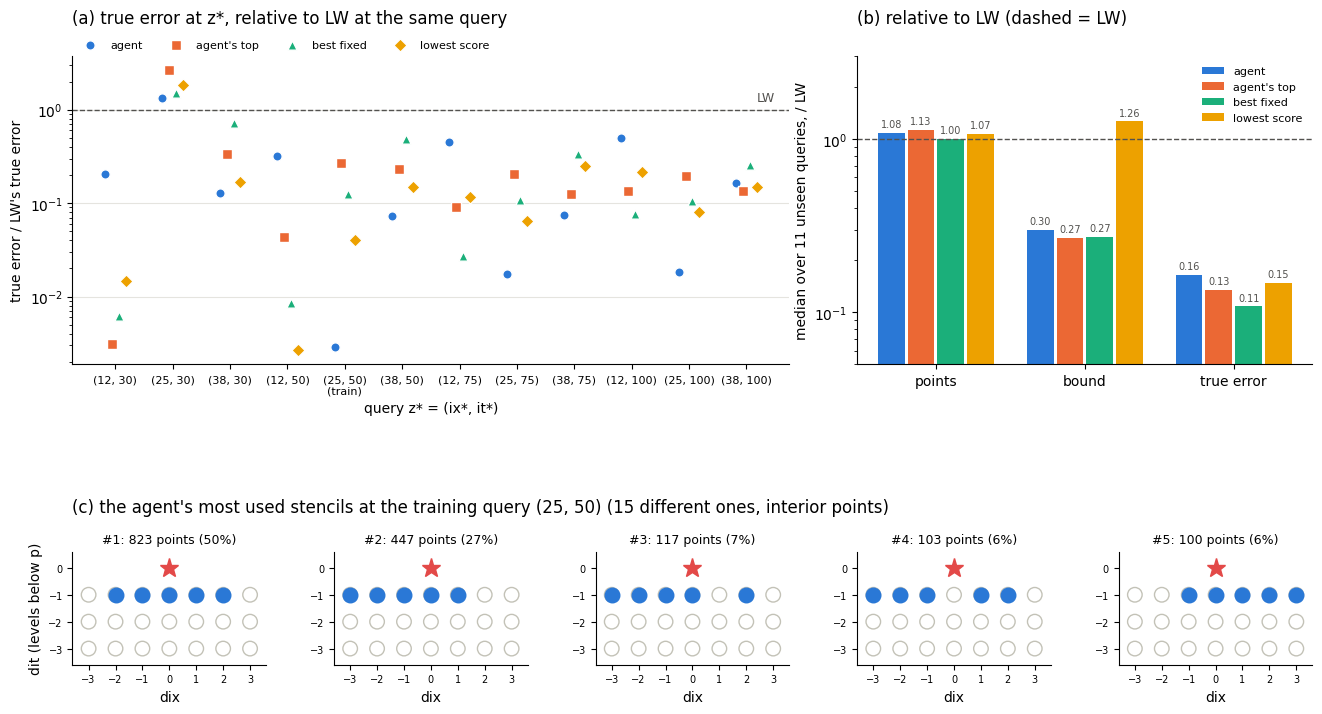

In [12]:
# ── Figure: Test 2 results (uses rows, used, QUERIES_TEST, Z_TRAIN from the Test 2 cell) ──
#   (a) true error of each method relative to LW, query by query (below 1 = better than LW)
#   (b) median over the unseen queries: points, bound and true error, each relative to LW
#   (c) the stencils the agent uses most at the training query (window cells, p = red star)
METHODS = ["agent", "agent's top", "best fixed", "lowest score"]
COLORS  = {"agent": "#2a78d6", "agent's top": "#eb6834", "best fixed": "#1baf7a", "lowest score": "#eda100"}
MARKERS = {"agent": "o", "agent's top": "s", "best fixed": "^", "lowest score": "D"}
get = lambda z, n: next(x for x in rows if x["z"] == z and x["method"] == n)
ratio = lambda z, n, k: get(z, n)[k] / get(z, "LW")[k]
unseen = [z for z in QUERIES_TEST if z != Z_TRAIN]

fig = plt.figure(figsize=(16, 8.5))
gs = fig.add_gridspec(2, 5, height_ratios=[1.5, 1], hspace=0.55, wspace=0.35)

# (a) per query
ax = fig.add_subplot(gs[0, :3])
xs = np.arange(len(QUERIES_TEST))
for j, n in enumerate(METHODS):
    ax.scatter(xs + (j - 1.5) * 0.12, [ratio(z, n, "error") for z in QUERIES_TEST], s=45, marker=MARKERS[n],
               color=COLORS[n], edgecolor="white", linewidth=1, label=n, zorder=3)
ax.axhline(1, color="#52514e", lw=1, ls="--", zorder=1)
ax.text(len(QUERIES_TEST) - 0.5, 1.15, "LW", color="#52514e", ha="right", va="bottom", fontsize=9)
ax.set_yscale("log"); ax.set_xticks(xs)
ax.set_xticklabels([f"{z}\n(train)" if z == Z_TRAIN else str(z) for z in QUERIES_TEST], fontsize=8)
ax.set_xlabel("query z* = (ix*, it*)"); ax.set_ylabel("true error / LW's true error")
ax.set_title("(a) true error at z*, relative to LW at the same query", loc="left", pad=24)
ax.grid(axis="y", which="major", color="#e5e4df", lw=0.8); ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False); ax.legend(fontsize=8, frameon=False, ncol=4, loc="lower left", bbox_to_anchor=(0, 1.0), borderaxespad=0.2)

# (b) medians over the unseen queries
ax = fig.add_subplot(gs[0, 3:])
keys = [("points", "points"), ("bound", "bound"), ("error", "true error")]
w = 0.2
for j, n in enumerate(METHODS):
    med = [np.median([ratio(z, n, k) for z in unseen]) for k, _ in keys]
    bars = ax.bar(np.arange(3) + (j - 1.5) * w, med, width=w - 0.02, color=COLORS[n], label=n)
    for b, v in zip(bars, med):
        ax.text(b.get_x() + b.get_width() / 2, v * 1.05, f"{v:.2f}", ha="center", va="bottom", fontsize=7, color="#52514e")
ax.axhline(1, color="#52514e", lw=1, ls="--")
ax.set_xticks(np.arange(3)); ax.set_xticklabels([l for _, l in keys])
ax.set_ylabel("median over 11 unseen queries, / LW"); ax.set_yscale("log"); ax.set_ylim(0.05, 3)
ax.set_title("(b) relative to LW (dashed = LW)", loc="left", pad=24)
ax.spines[["top", "right"]].set_visible(False); ax.legend(fontsize=8, frameon=False, loc="upper right")

# (c) the agent's most used stencils
total = sum(used.values())
for i, (s, cnt) in enumerate(used.most_common(5)):
    ax = fig.add_subplot(gs[1, i])
    ax.scatter(*np.array(WINDOW).T, s=110, facecolors="none", edgecolors="#c3c2b7")
    ax.scatter(*np.array([WINDOW[k] for k in s]).T, s=110, color=COLORS["agent"])
    ax.plot(0, 0, "*", color="#e34948", ms=14)
    ax.set_xlim(-3.6, 3.6); ax.set_ylim(-3.6, 0.6); ax.set_aspect("equal")
    ax.set_xticks(range(-3, 4)); ax.set_yticks([0, -1, -2, -3]); ax.tick_params(labelsize=7)
    ax.set_title(f"#{i + 1}: {cnt} points ({cnt / total:.0%})", fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)
    if i == 0:
        ax.set_ylabel("dit (levels below p)")
        ax.text(0, 1.35, f"(c) the agent's most used stencils at the training query {Z_TRAIN} "
                f"({len(used)} different ones, interior points)", transform=ax.transAxes, fontsize=12)
    ax.set_xlabel("dix")
plt.show()

z* = (25, 50): 50 s (guess cost 105 points, added to every map method)
z* = (38, 75): 68 s (guess cost 150 points, added to every map method)
z* = (25, 100): 93 s (guess cost 210 points, added to every map method)

z* = (25, 50), t* = 0.091
                    FD-3:    1824 points | true error 2.1e-03
                      LW:    1824 points | true error 7.3e-04
                      CN:     576 points | true error 4.5e-03
              FD-5 + RK4:    9228 points | true error 1.1e-06
             WENO5 + RK3:   15579 points | true error 1.3e-06
                  LW map:    1929 points | true error 3.9e-04 | bound 5.7e-04
            lowest score:    2068 points | true error 1.6e-05 | bound 4.1e-04
                  greedy:     939 points | true error 5.2e-05 | bound 4.3e-04
    agent (from scratch):    2004 points | true error 1.1e-06 | bound 1.3e-04
     agent (clone + PPO):    1695 points | true error 1.7e-04 | bound 2.9e-04

z* = (38, 75), t* = 0.136
                    FD-3:    284

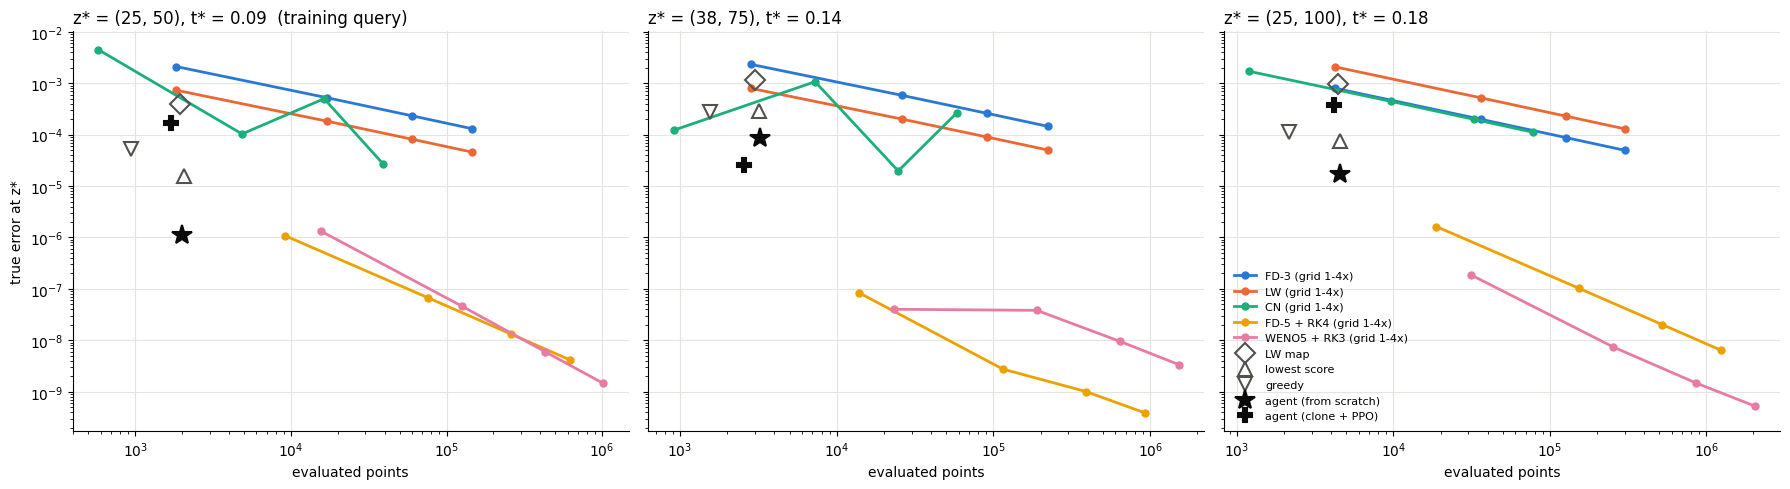

In [13]:
# ══ Comparison with classical solvers: true error at z* vs evaluated points ══
#   Classical schemes run on their own grids, refined k = 1..4 (r = alpha dt/dx^2 kept fixed), with the same boundary data
#   (inflow / outflow Dirichlet values g_left, g_right in time). Burgers: each grid point uses its own value as the speed.
#     FD-3: forward Euler + central 2nd order | LW: Lax-Wendroff | CN: Crank-Nicolson (speed from the previous step)
#     FD-5 + RK4: 4th-order central in space, RK4 in time | WENO5 + RK3: WENO5-JS (Lax-Friedrichs splitting) + SSP-RK3,
#     its ghost nodes past the walls taken from u_true (more data than the others get: this favours WENO).
#   Evaluated points = grid values computed in z*'s dependency cone (RK: x stages; CN: the whole row, it is implicit).
#   Map methods run on the base grid; they also pay for the guess levels up to t*. u_true ONLY for reporting (and WENO ghosts).
from scipy.linalg import solve_banded
_gd = _gs.derivative()                                            # time derivative of the boundary data (RK stages)

def _weno5(vm2, vm1, v0, vp1, vp2):
    """WENO5-JS value at the interface on the vp1 side of v0."""
    q0, q1, q2 = (2 * vm2 - 7 * vm1 + 11 * v0) / 6, (-vm1 + 5 * v0 + 2 * vp1) / 6, (2 * v0 + 5 * vp1 - vp2) / 6
    b0 = 13 / 12 * (vm2 - 2 * vm1 + v0)**2 + 0.25 * (vm2 - 4 * vm1 + 3 * v0)**2
    b1 = 13 / 12 * (vm1 - 2 * v0 + vp1)**2 + 0.25 * (vm1 - vp1)**2
    b2 = 13 / 12 * (v0 - 2 * vp1 + vp2)**2 + 0.25 * (3 * v0 - 4 * vp1 + vp2)**2
    w0, w1, w2 = 0.1 / (1e-6 + b0)**2, 0.6 / (1e-6 + b1)**2, 0.3 / (1e-6 + b2)**2
    return (w0 * q0 + w1 * q1 + w2 * q2) / (w0 + w1 + w2)

def rhs(u, h, t, scheme):
    """du/dt at the nodes (walls: the time derivative of the boundary data)."""
    n = len(u)
    if scheme == "WENO5 + RK3":
        ue = np.r_[u_true(-h * np.arange(3, 0, -1), t), u, u_true(1 + h * np.arange(1, 4), t)]   # ue[j] = node j - 3
        am = np.abs(ue).max()
        fp, fm = 0.5 * (0.5 * ue**2 + am * ue), 0.5 * (0.5 * ue**2 - am * ue)
        j = np.arange(2, n + 3)
        F = _weno5(fp[j - 2], fp[j - 1], fp[j], fp[j + 1], fp[j + 2]) + _weno5(fm[j + 3], fm[j + 2], fm[j + 1], fm[j], fm[j - 1])
        c = np.arange(3, n + 3)
        du = -(F[1:] - F[:-1]) / h + alpha * (-ue[c + 2] + 16 * ue[c + 1] - 30 * ue[c] + 16 * ue[c - 1] - ue[c - 2]) / (12 * h**2)
    else:                                                          # FD-5: 4th-order central, 2nd order next to the walls
        u2, u1 = np.zeros(n), np.zeros(n)
        u2[1:-1], u1[1:-1] = u[2:] - 2 * u[1:-1] + u[:-2], (u[2:] - u[:-2]) / 2
        u2[2:-2] = (-u[4:] + 16 * u[3:-1] - 30 * u[2:-2] + 16 * u[1:-3] - u[:-4]) / 12
        u1[2:-2] = (-u[4:] + 8 * u[3:-1] - 8 * u[1:-3] + u[:-4]) / 12
        du = alpha * u2 / h**2 - u * u1 / h
    du[0], du[-1] = _gd(t)
    return du

def classical(scheme, k, z):
    """(evaluated points, true error at z*) on the grid refined k times."""
    n, h = (nx - 1) * k + 1, dx / k
    t_star, ix = z[1] * dt, z[0] * k
    u = u0(np.arange(n) * h)
    if scheme == "WENO5 + RK3":                                    # its own stable step: CFL 0.4, diffusion number 0.2
        steps = int(np.ceil(t_star / min(0.4 * h / A_MAX, 0.2 * h**2 / alpha))); tau_k = t_star / steps
    else:
        tau_k = dt / k**2 if scheme != "CN" else 4 * dt / k**2     # CN is implicit: 4x bigger steps
        steps = round(t_star / tau_k)
    r = alpha * tau_k / h**2
    for j in range(steps):
        t, t1 = j * tau_k, (j + 1) * tau_k
        if scheme == "WENO5 + RK3":
            u1 = u + tau_k * rhs(u, h, t, scheme)
            u2 = 0.75 * u + 0.25 * (u1 + tau_k * rhs(u1, h, t1, scheme))
            u = u / 3 + 2 / 3 * (u2 + tau_k * rhs(u2, h, t + tau_k / 2, scheme))
        elif scheme == "FD-5 + RK4":
            k1 = rhs(u, h, t, scheme); k2 = rhs(u + tau_k * k1 / 2, h, t + tau_k / 2, scheme)
            k3 = rhs(u + tau_k * k2 / 2, h, t + tau_k / 2, scheme); k4 = rhs(u + tau_k * k3, h, t1, scheme)
            u = u + tau_k * (k1 + 2 * k2 + 2 * k3 + k4) / 6
        else:
            nu = u[1:-1] * tau_k / h
            d2, d1 = u[2:] - 2 * u[1:-1] + u[:-2], (u[2:] - u[:-2]) / 2
            new = u.copy()
            if scheme == "FD-3":
                new[1:-1] = u[1:-1] + r * d2 - nu * d1
            elif scheme == "LW":
                new[1:-1] = u[1:-1] + (r + nu**2 / 2) * d2 - nu * d1
            elif scheme == "CN":                                   # speed from the previous step (linearised CN)
                lo, up = -r / 2 - nu / 4, -r / 2 + nu / 4          # coefficients of u_{i-1}, u_{i+1} at the new time
                b = u[1:-1] + r / 2 * d2 - nu / 2 * d1
                b[0] -= lo[0] * g_left(t1); b[-1] -= up[-1] * g_right(t1)
                ab = np.zeros((3, n - 2)); ab[0, 1:], ab[1], ab[2, :-1] = up[:-1], 1 + r, lo[1:]
                new[1:-1] = solve_banded((1, 1), ab, b)
            new[0], new[-1] = g_left(t1), g_right(t1)
            u = new
    err = abs(u[ix] - Ug(z))
    spread = {"FD-3": 1, "LW": 1, "FD-5 + RK4": 8, "WENO5 + RK3": 9}.get(scheme)   # cone growth per step (RK: all stages)
    if spread is None:
        pts = (n - 2) * steps                                      # CN couples the whole row at every step
    else:
        pts = sum(min(n - 2, ix + spread * j) - max(1, ix - spread * j) + 1 for j in range(steps))
        pts *= {"FD-5 + RK4": 4, "WENO5 + RK3": 3}.get(scheme, 1)
    return pts, err

# ── All methods at a few queries ──
SCHEMES = ["FD-3", "LW", "CN", "FD-5 + RK4", "WENO5 + RK3"]
Z_CMP   = [(25, 50), (38, 75), (25, 100)]                         # the training query and two unseen ones
AGENTS  = {"agent (from scratch)": ("inflow_smooth_scratch_gae0.97_z25-50_lam1-1", "ppo_final"),
           "agent (clone + PPO)":  ("inflow_smooth_imitation_z25-50_lam1", "ppo_final")}
agents  = {name: MaskablePPO.load(os.path.join("runs10-15", folder, "checkpoints", f), device="cpu") for name, (folder, f) in AGENTS.items()}
cmp = []
for z in Z_CMP:
    t0 = time.time()
    for scheme in SCHEMES:
        for k in (1, 2, 3, 4):
            pts, err = classical(scheme, k, z)
            cmp.append(dict(z=z, method=scheme, k=k, points=pts, error=err))
    guess_cost = (len(xc) - 2) * int(np.ceil(z[1] * dt / tau))     # guess levels up to t*, interior coarse points
    maps = {"LW map": build_map(z, lw), "lowest score": build_map(z, lowest_score), "greedy": build_map(z, greedy_rule(1.0))}
    maps.update({name: run_policy(model, z, 1.0).m for name, model in agents.items()})
    for name, m in maps.items():
        rep = report(m)
        cmp.append(dict(z=z, method=name, k=1, points=rep["points"] + guess_cost, error=rep["error"], bound=rep["bound"]))
    print(f"z* = {z}: {time.time() - t0:.0f} s (guess cost {guess_cost} points, added to every map method)")

# ── Table: each map method vs the classical schemes at the base grid (k = 1) ──
for z in Z_CMP:
    print(f"\nz* = {z}, t* = {z[1] * dt:.3f}")
    for c in cmp:
        if c["z"] == z and c["k"] == 1:
            extra = f" | bound {c['bound']:.1e}" if "bound" in c else ""
            print(f"  {c['method']:>22s}: {c['points']:7d} points | true error {c['error']:.1e}{extra}")

# ── Figure: true error vs evaluated points, one panel per query ──
COL = {"FD-3": "#2a78d6", "LW": "#eb6834", "CN": "#1baf7a", "FD-5 + RK4": "#eda100", "WENO5 + RK3": "#e87ba4"}
MK  = {"LW map": "D", "lowest score": "^", "greedy": "v", "agent (from scratch)": "*", "agent (clone + PPO)": "P"}
fig, axes = plt.subplots(1, len(Z_CMP), figsize=(6 * len(Z_CMP), 5), sharey=True)
for ax, z in zip(axes, Z_CMP):
    for s in SCHEMES:
        pts = sorted((c["points"], c["error"]) for c in cmp if c["z"] == z and c["method"] == s)
        ax.loglog(*zip(*pts), "o-", color=COL[s], lw=2, ms=5, label=f"{s} (grid 1-4x)")
    for name, mk in MK.items():
        c = next(c for c in cmp if c["z"] == z and c["method"] == name)
        ax.loglog(c["points"], c["error"], mk, color="#0b0b0b" if "agent" in name else "#52514e",
                  ms=15 if mk == "*" else 10, mfc="#0b0b0b" if "agent" in name else "none", mew=1.5, label=name)
    ax.set_title(f"z* = {z}, t* = {z[1] * dt:.2f}" + ("  (training query)" if z == (25, 50) else ""), loc="left")
    ax.set_xlabel("evaluated points"); ax.grid(True, which="major", color="#e5e4df", lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("true error at z*"); axes[-1].legend(fontsize=8, frameon=False, loc="lower left")
plt.tight_layout(); plt.show()

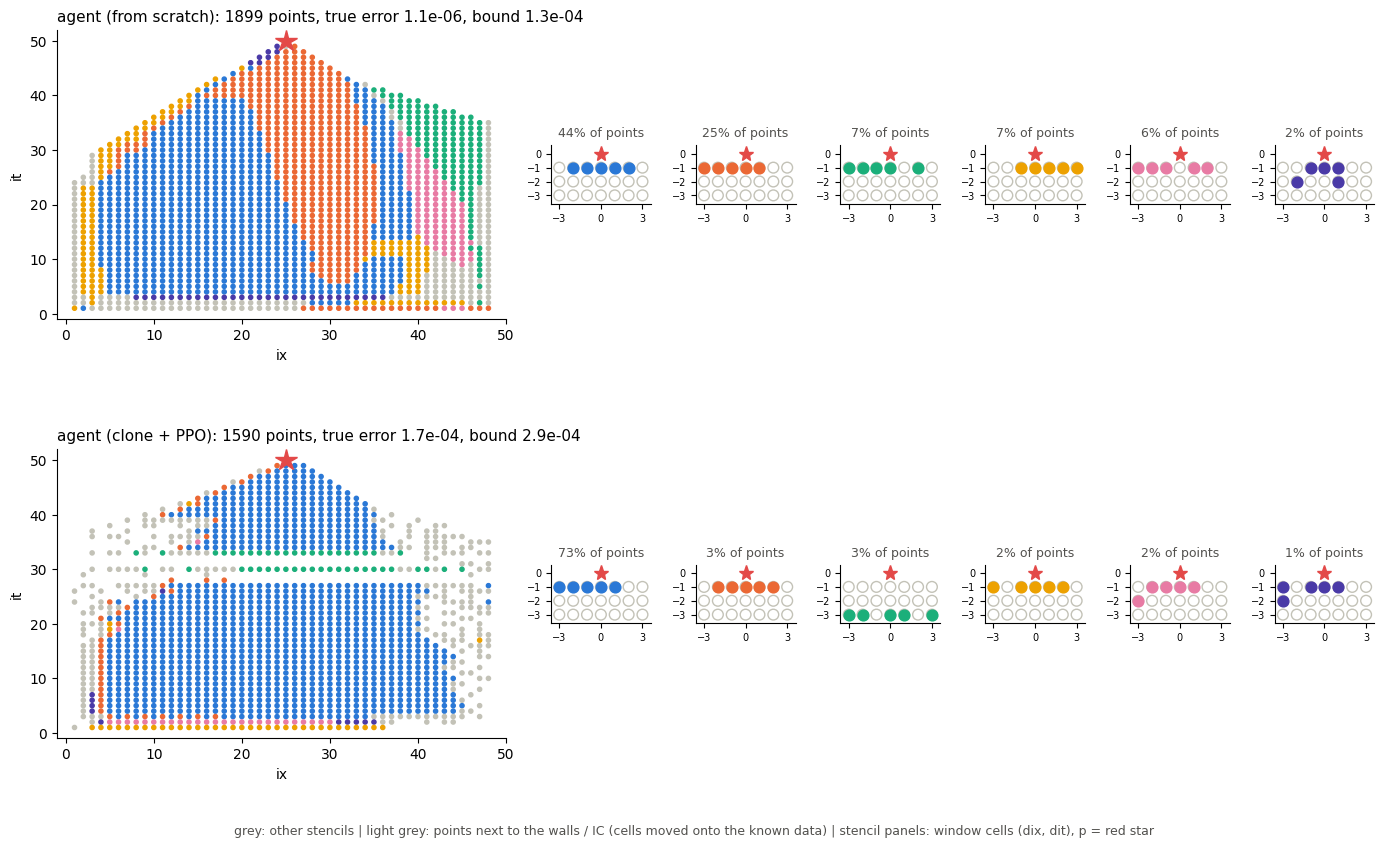

In [14]:
# ── Which stencil is used where: each agent's map at z*, every point coloured by its stencil (the 6 most used + other) ──
Z_SHOW = (25, 50)
AGENTS = {"agent (from scratch)": ("inflow_smooth_scratch_gae0.97_z25-50_lam1-1", "ppo_final"),
          "agent (clone + PPO)":  ("inflow_smooth_imitation_z25-50_lam1", "ppo_final")}
TOP_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"]
OTHER, EDGE = "#c3c2b7", "#e5e4df"                                # other stencils, points next to the walls / IC

def stencil_cells(p, nbs):
    """Window cells of p's stencil, or None next to the walls / IC (cells there are moved onto the known data)."""
    offs = [(q[0] - p[0], q[1] - p[1]) for q in nbs]
    return tuple(sorted(WINDOW.index(o) for o in offs)) if all(o in WINDOW for o in offs) else None

fig = plt.figure(figsize=(17, 4.6 * len(AGENTS)))
gs = fig.add_gridspec(len(AGENTS), 7, width_ratios=[4.5, 1, 1, 1, 1, 1, 1], hspace=0.45, wspace=0.3)
for row, (name, (folder, f)) in enumerate(AGENTS.items()):
    m = run_policy(MaskablePPO.load(os.path.join("runs10-15", folder, "checkpoints", f), device="cpu"), Z_SHOW, 1.0).m
    cells = {p: stencil_cells(p, nbs) for p, (nbs, w) in m["stencil"].items()}
    count = Counter(c for c in cells.values() if c is not None)
    top6 = [c for c, _ in count.most_common(6)]
    color = {c: TOP_COLORS[i] for i, c in enumerate(top6)}
    rep = report(m)

    # the map: every computed point, coloured by its stencil
    ax = fig.add_subplot(gs[row, 0])
    P = np.array(list(cells))
    ax.scatter(P[:, 0], P[:, 1], s=9, c=[EDGE if c is None else color.get(c, OTHER) for c in cells.values()])
    ax.plot(*Z_SHOW, "*", color="#e34948", ms=16)
    ax.set_xlim(-1, nx); ax.set_ylim(-1, Z_SHOW[1] + 2); ax.set_xlabel("ix"); ax.set_ylabel("it")
    ax.set_title(f"{name}: {rep['points']} points, true error {rep['error']:.1e}, bound {rep['bound']:.1e}", loc="left", fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)

    # the 6 most used stencils, in the same colours
    total = sum(count.values())
    for i, c in enumerate(top6):
        g = fig.add_subplot(gs[row, i + 1])
        g.scatter(*np.array(WINDOW).T, s=60, facecolors="none", edgecolors=OTHER)
        g.scatter(*np.array([WINDOW[k] for k in c]).T, s=60, color=TOP_COLORS[i])
        g.plot(0, 0, "*", color="#e34948", ms=11)
        g.set_xlim(-3.6, 3.6); g.set_ylim(-3.6, 0.6); g.set_aspect("equal")
        g.set_xticks([-3, 0, 3]); g.set_yticks([0, -1, -2, -3]); g.tick_params(labelsize=7)
        g.set_title(f"{count[c] / total:.0%} of points", fontsize=9, color="#52514e")
        g.spines[["top", "right"]].set_visible(False)
fig.text(0.5, 0.005, "grey: other stencils | light grey: points next to the walls / IC (cells moved onto the known data) | "
         "stencil panels: window cells (dix, dit), p = red star", ha="center", fontsize=9, color="#52514e")
plt.show()

top-1: [(-2, -1), (-1, -1), (0, -1), (1, -1), (2, -1)] | top-2: [(-3, -1), (-2, -1), (-1, -1), (0, -1), (1, -1)]
1295 points | the agent picked the locally better of the two at 43% of them (always-top-1 would get 36%)


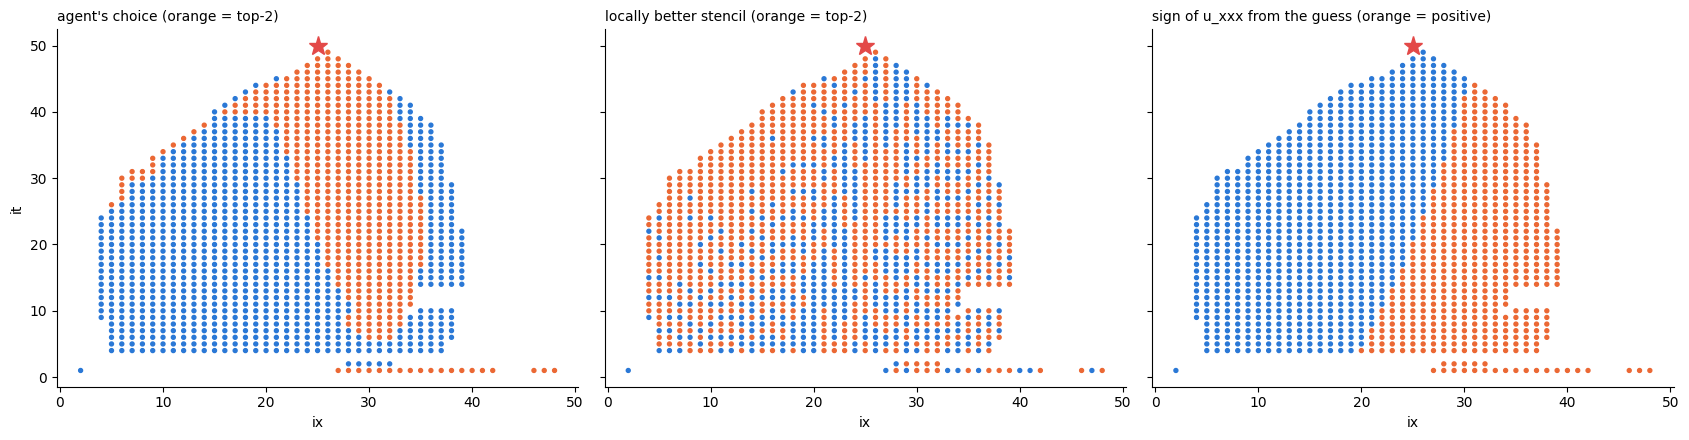

In [25]:
# ── Does the agent pick the locally better of its two main stencils? (one map; u_true ONLY for this check) ──
#   At every interior point where the agent used its top-1 or top-2 stencil, compute the true local error of BOTH
#   (delta = u_p - sum w_q u_q, weights with the guessed speed as in the map) and see which is smaller.
from collections import Counter
Z_CHK = (25, 50)
m_chk = run_policy(model, Z_CHK, 1.0).m
def cells_of(p, nbs):
    offs = [(q[0] - p[0], q[1] - p[1]) for q in nbs]
    return tuple(sorted(WINDOW.index(o) for o in offs)) if all(o in WINDOW for o in offs) else None
cnt = Counter(c for c in (cells_of(p, nbs) for p, (nbs, w) in m_chk["stencil"].items()) if c is not None)
s1, s2 = [c for c, _ in cnt.most_common(2)]
print("top-1:", [WINDOW[k] for k in s1], "| top-2:", [WINDOW[k] for k in s2])

def local_err(p, s):
    nbs = [place(p, k) for k in s]
    w = weights(p, nbs)
    return np.inf if w is None else abs(Ug(p) - w @ np.array([Ug(q) for q in nbs]))

P, chose, better, uxxx = [], [], [], []
for p, (nbs, w) in m_chk["stencil"].items():
    c = cells_of(p, nbs)
    if c in (s1, s2):
        e1, e2 = local_err(p, s1), local_err(p, s2)
        P.append(p); chose.append(c == s2); better.append(e2 < e1); uxxx.append(guess_derivs(p)[3])
P, chose, better, uxxx = np.array(P), np.array(chose), np.array(better), np.array(uxxx)
print(f"{len(P)} points | the agent picked the locally better of the two at {np.mean(chose == better):.0%} of them "
      f"(always-top-1 would get {np.mean(~better):.0%})")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for ax, vals, title in [(axes[0], chose, "agent's choice (orange = top-2)"),
                        (axes[1], better, "locally better stencil (orange = top-2)"),
                        (axes[2], uxxx > 0, "sign of u_xxx from the guess (orange = positive)")]:
    ax.scatter(P[:, 0], P[:, 1], s=8, c=np.where(vals, "#eb6834", "#2a78d6"))
    ax.plot(*Z_CHK, "*", color="#e34948", ms=14); ax.set_title(title, loc="left", fontsize=10)
    ax.set_xlabel("ix"); ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("it"); plt.tight_layout(); plt.show()

In [26]:
# ══ Checking the claims about the agent's two stencils ══
#   Claim A: the agent uses the shifted row (top-2) where the guessed slope u_x < 0, the centred row (top-1) where u_x >= 0.
#   Claim B: on this solution, sign(u_xxx) = -sign(u_x), so A is the same as "shifted where u_xxx > 0" (the right panel).
#   Claim C: that simple slope rule, used everywhere, is as good as the agent's map, and better than either stencil alone.
#   Oracle = per point, the stencil with the smaller TRUE local error (u_true): a diagnostic only, not a method.
ux = np.array([guess_derivs(tuple(p))[1] for p in P])
print(f"A: agent's choice agrees with 'top-2 where u_x < 0' at {np.mean(chose == (ux < 0)):.0%} of the {len(P)} points")
print(f"B: sign(u_xxx) = -sign(u_x) at {np.mean((uxxx > 0) == (ux < 0)):.0%} of the points")

_as_set2 = {}
def use_or_fallback(m, p, s):
    """Stencil s at p if admissible there, else p's lowest-score stencil (as for the fixed stencils in Test 2)."""
    sets = admissible(p)[0]
    if id(sets) not in _as_set2:
        _as_set2[id(sets)] = set(sets)
    return [place(p, k) for k in s] if s in _as_set2[id(sets)] else lowest_score(m, p)

rules = {"LW": lw,
         "agent": None,
         "always top-1": lambda m, p: use_or_fallback(m, p, s1),
         "always top-2": lambda m, p: use_or_fallback(m, p, s2),
         "slope rule": lambda m, p: use_or_fallback(m, p, s2 if guess_derivs(p)[1] < 0 else s1),
         "oracle (locally better)": lambda m, p: use_or_fallback(m, p, s2 if local_err(p, s2) < local_err(p, s1) else s1)}

print("\nC: true error at z* (and points, bound) for each rule")
for z in [(25, 50), (38, 75), (25, 100)]:
    print(f"\nz* = {z}" + ("  (training query)" if z == (25, 50) else "  (unseen)"))
    for name, rule in rules.items():
        m_ = run_policy(model, z, 1.0).m if rule is None else build_map(z, rule)
        rep = report(m_)
        print(f"  {name:>24s}: {rep['points']:5d} points | true error {rep['error']:.1e} | bound {rep['bound']:.1e}")

A: agent's choice agrees with 'top-2 where u_x < 0' at 72% of the 1295 points
B: sign(u_xxx) = -sign(u_x) at 87% of the points

C: true error at z* (and points, bound) for each rule

z* = (25, 50)  (training query)
                        LW:  1824 points | true error 3.9e-04 | bound 5.7e-04
                     agent:  1899 points | true error 1.1e-06 | bound 1.3e-04
              always top-1:  2100 points | true error 1.1e-04 | bound 1.3e-04
              always top-2:  2016 points | true error 1.6e-04 | bound 2.3e-04
                slope rule:  1990 points | true error 5.3e-05 | bound 1.2e-04
   oracle (locally better):  2090 points | true error 6.6e-05 | bound 1.8e-04

z* = (38, 75)  (unseen)
                        LW:  2842 points | true error 1.1e-03 | bound 1.3e-03
                     agent:  3085 points | true error 8.4e-05 | bound 3.2e-04
              always top-1:  3209 points | true error 1.4e-04 | bound 3.8e-04
              always top-2:  3298 points | true error 8.5e

In [28]:
# ══ What in the state drives the agent's choice between its two main stencils? ══
#   Record the state at the FIRST pick of every point (forced points have none), then:
#   (1) how much the state actually varies between points; (2) the best 1- and 2-level threshold rules ("decision trees")
#   that predict top-1 vs top-2 from single features. A short, accurate rule = the policy responds to few, smooth features.
FEAT = ([f"picked[{WINDOW[k]}]" for k in range(N_CELLS)] + [f"exists[{WINDOW[k]}]" for k in range(N_CELLS)]
        + [f"known[{WINDOW[k]}]" for k in range(N_CELLS)]
        + ["log10|beta|", "height / z*_t", "offset to z* / nx", "dist left wall", "dist right wall", "u", "u_x * L",
           "u_xx * L^2", "points used / N_LW", "pending / N_LW", "pending influence", "log10 lam"])

env = MapEnv(queries=[(25, 50)], lam_range=(1.0, 1.0))
obs, _ = env.reset(seed=0)
first_obs, done = {}, False
while not done:
    if not env.picks:
        first_obs[next_point(env.m)] = obs.copy()                    # the state when this point's first cell is picked
    act, _ = model.predict(obs, action_masks=env.action_masks(), deterministic=True)
    obs, _, done, _, _ = env.step(act)
pts = [p for p in first_obs if cells_of(p, env.m["stencil"][p][0]) in (s1, s2)]
X = np.array([first_obs[p] for p in pts]); y = np.array([cells_of(p, env.m["stencil"][p][0]) == s2 for p in pts])
print(f"{len(pts)} points that used top-1 or top-2 | top-2 at {y.mean():.0%} | always guessing the majority: {max(y.mean(), 1 - y.mean()):.0%}")

# ── (1) how much does the state vary? ──
cell_part = X[:, :3 * N_CELLS]
print(f"\nper-cell part (picked/exists/known, {3 * N_CELLS} numbers): {len(np.unique(cell_part, axis=0))} distinct patterns over {len(pts)} points")
print("global features that vary (min .. max):")
for j in range(3 * N_CELLS, X.shape[1]):
    if X[:, j].std() > 1e-9:
        print(f"  {FEAT[j]:>20s}: {X[:, j].min():9.3f} .. {X[:, j].max():9.3f}")

# ── (2) best threshold rules ──
def best_stump(Xs, ys, cols):
    """Best single threshold rule 'top-2 if x_j > t' (or <= t): (accuracy, j, t, direction)."""
    best = (max(ys.mean(), 1 - ys.mean()), None, None, None)
    for j in cols:
        for t in np.unique(np.quantile(Xs[:, j], np.linspace(0.02, 0.98, 49))):
            for sign in (1, -1):
                acc = np.mean((sign * (Xs[:, j] - t) > 0) == ys)
                if acc > best[0]:
                    best = (acc, j, t, sign)
    return best

cols = [j for j in range(X.shape[1]) if X[:, j].std() > 1e-9]
print("\nbest single-feature rules:")
singles = sorted((best_stump(X, y, [j]) + (j,) for j in cols), key=lambda r: -r[0])[:6]
for acc, j, t, sign, _ in singles:
    print(f"  {acc:5.0%}  top-2 if {FEAT[j]} {'>' if sign > 0 else '<='} {t:.3f}")

best2 = (0, None)
for acc1, j1, t1, s1_, _ in singles[:4]:                            # 2 levels: split on a good feature, then best rule per side
    side = s1_ * (X[:, j1] - t1) > 0
    acc = 0
    for mask in (side, ~side):
        if mask.sum():
            a, j2, t2, s2_ = best_stump(X[mask], y[mask], cols)
            acc += a * mask.mean()
    if acc > best2[0]:
        best2 = (acc, FEAT[j1])
print(f"\nbest 2-level rule (first split on '{best2[1]}'): {best2[0]:.0%} accuracy")

1294 points that used top-1 or top-2 | top-2 at 36% | always guessing the majority: 64%

per-cell part (picked/exists/known, 63 numbers): 12 distinct patterns over 1294 points
global features that vary (min .. max):
           log10|beta|:    -5.169 ..    -0.511
         height / z*_t:     0.020 ..     0.980
     offset to z* / nx:    -0.460 ..     0.440
        dist left wall:     0.040 ..     0.940
       dist right wall:     0.040 ..     0.940
                     u:     0.389 ..     1.789
               u_x * L:    -0.356 ..     0.327
            u_xx * L^2:    -0.151 ..     0.109
    points used / N_LW:     0.002 ..     1.040
        pending / N_LW:     0.001 ..     0.038
     pending influence:     0.000 ..     1.000

best single-feature rules:
    93%  top-2 if exists[(1, -1)] <= 1.000
    79%  top-2 if pending / N_LW <= 0.027
    78%  top-2 if offset to z* / nx > -0.040
    78%  top-2 if dist left wall > 0.460
    78%  top-2 if dist right wall <= 0.520
    72%  top-2 if u_x * L

In [15]:
# ══ Cost of choosing the stencils: wall time to build a map, per point, and decisions per point ══
#   The stencil table (all admissible stencils per geometry and speed) is built once and cached; it is shared by
#   the rules AND by the agent's action mask, so it is filled first and not counted.
#   decisions: rules score every admissible stencil at every point; the agent makes one network call per pick.
Z_COST, LAM = [(25, 50), (25, 100)], 1.0

def play_agent(z):
    """One deterministic episode; returns the map and the number of network calls."""
    env = MapEnv(queries=[z], lam_range=(LAM, LAM))
    obs, _ = env.reset(seed=0)
    done, calls = False, 0
    while not done:
        act, _ = model.predict(obs, action_masks=env.action_masks(), deterministic=True)
        obs, _, done, _, _ = env.step(act)
        calls += 1
    return env.m, calls

for z in Z_COST:
    for it in range(1, z[1] + 1):                                  # warm the stencil table below z*
        for ix in range(1, nx - 1):
            admissible((ix, it))
    print(f"\nz* = {z}")
    print(f"{'method':>14s} | {'points':>6s} | {'build time':>10s} | {'ms / point':>10s} | {'decisions / point':>18s}")
    for name, rule in [("LW", lw), ("lowest score", lowest_score), ("greedy", greedy_rule(LAM)), ("agent", None)]:
        t0 = time.time()
        if rule is None:
            m, calls = play_agent(z)
            decisions = f"{calls / len(m['stencil']):.1f} network calls"
        else:
            m = build_map(z, rule)
            decisions = "0" if rule is lw else f"{np.mean([len(admissible(p)[0]) for p in m['stencil']]):,.0f} stencils scored"
        sec = time.time() - t0
        print(f"{name:>14s} | {len(m['stencil']):6d} | {sec:9.2f}s | {1e3 * sec / len(m['stencil']):10.2f} | {decisions:>18s}")

# ── the two elementary costs, measured alone ──
obs = MapEnv(queries=[Z_COST[0]], lam_range=(LAM, LAM)).reset(seed=0)[0]
mask = np.ones(N_CELLS, dtype=bool)
t0 = time.time()
for _ in range(1000):
    model.predict(obs, action_masks=mask, deterministic=True)
t_net = (time.time() - t0) / 1000
sets, uses, sc = admissible(Z_COST[0])
t0 = time.time()
for _ in range(1000):
    admissible(Z_COST[0]); np.argmin(sc)
t_score = (time.time() - t0) / 1000
print(f"\none network call: {1e3 * t_net:.3f} ms | scoring all {len(sets):,} stencils at one point: {1e3 * t_score:.3f} ms")


z* = (25, 50)
        method | points | build time | ms / point |  decisions / point
            LW |   1824 |      0.02s |       0.01 |                  0
  lowest score |   1963 |      0.40s |       0.20 | 16,982 stencils scored
        greedy |    834 |      0.48s |       0.57 | 17,801 stencils scored
         agent |   1899 |      7.06s |       3.72 |  5.0 network calls

z* = (25, 100)
        method | points | build time | ms / point |  decisions / point
            LW |   4224 |      0.03s |       0.01 |                  0
  lowest score |   4322 |      1.13s |       0.26 | 17,340 stencils scored
        greedy |   1952 |      1.12s |       0.57 | 18,133 stencils scored
         agent |   4314 |     15.90s |       3.69 |  5.0 network calls

one network call: 0.298 ms | scoring all 18,768 stencils at one point: 0.063 ms



z* = (25, 50), t* = 0.091: exact kernel mass 0.996, centre 0.359 (x* = 0.510), width 0.132
       method | IC mass   wall | L1 dist | neg mass | 3rd mom err 4th mom err | true error
           LW |   0.997  0.003 |   0.010 |    0.000 |    3.52e-05    2.62e-05 |    3.9e-04
        agent |   0.996  0.004 |   0.012 |   -0.000 |    6.57e-05    9.42e-06 |    1.1e-06
 lowest score |   0.997  0.003 |   0.268 |    0.000 |    1.01e-04    1.07e-05 |    1.6e-05
       greedy |   0.996  0.004 |   0.305 |   -0.000 |    4.41e-05    2.37e-06 |    5.2e-05
   best fixed |   0.996  0.004 |   0.178 |    0.000 |    4.79e-05    2.24e-06 |    4.9e-05

z* = (25, 100), t* = 0.182: exact kernel mass 0.878, centre 0.272 (x* = 0.510), width 0.148
       method | IC mass   wall | L1 dist | neg mass | 3rd mom err 4th mom err | true error
           LW |   0.882  0.118 |   0.010 |    0.000 |    7.80e-06    6.89e-05 |    9.4e-04
        agent |   0.884  0.116 |   0.023 |    0.000 |    1.35e-04    4.57e-05 |    1.7e

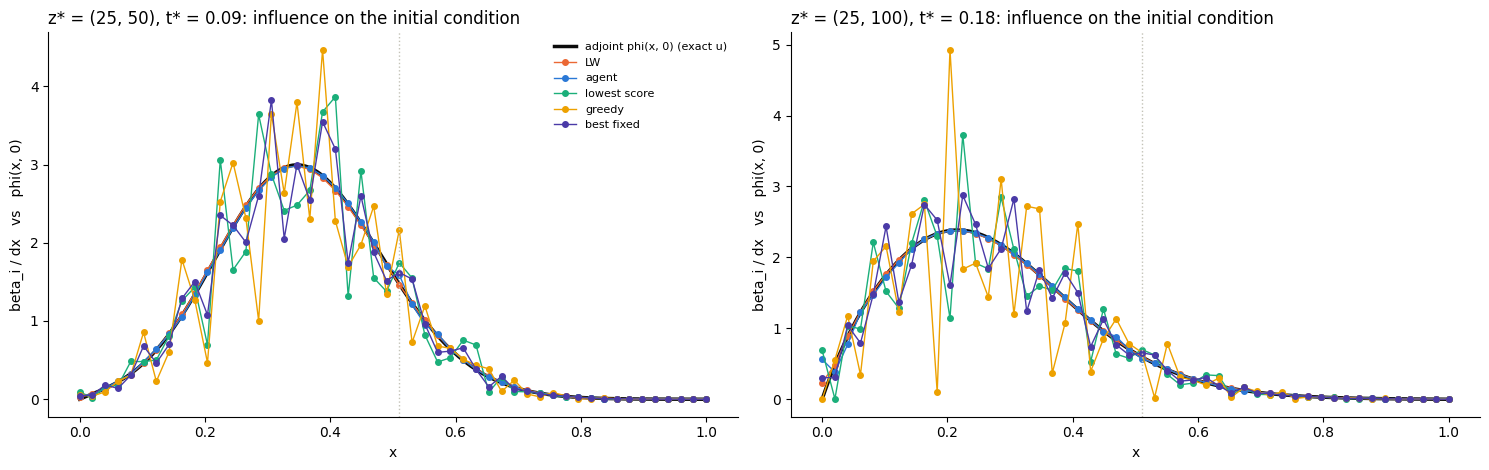

In [19]:
# ══ Is beta a Green's function? The map's influence on the initial condition vs the adjoint of linearised Burgers ══
#   beta_i = d u_hat(z*) / d u0(x_i): the map's discrete Green's function (with the weights the forward pass used).
#   Exact counterpart: phi(x, 0), where -phi_t - u phi_x = alpha phi_xx, phi(x, t*) = delta(x - x*), phi = 0 at the walls,
#   solved backward on a fine grid with the exact u (u_true ONLY here). Compare beta_i / dx with phi(x_i, 0).
#   Note: mass, centre and width are largely fixed by the Taylor conditions for ANY map; the shape beyond that
#   (3rd/4th moments, negative lobes, L1 distance) is where the maps differ.
Z_ADJ, NF = [(25, 50), (25, 100)], 201
xf = np.linspace(0.0, 1.0, NF); hf = xf[1] - xf[0]

def adjoint_ic(z):
    """phi(x, 0) on the fine grid xf (explicit, central differences, exact u linear in time between 41 tables)."""
    t_star = z[1] * dt
    steps = int(np.ceil(t_star / (0.4 * hf**2 / alpha))); s = t_star / steps
    t_tab = np.linspace(0.0, t_star, 41); U_tab = np.array([u_true(xf, t) for t in t_tab])
    phi = np.zeros(NF); phi[int(round(z[0] * dx / hf))] = 1.0 / hf          # discrete delta at x*
    for j in range(steps):
        t = t_star - j * s                                                  # march backward from t* to 0
        i = min(int(t / (t_tab[1] - t_tab[0])), len(t_tab) - 2); w = t / (t_tab[1] - t_tab[0]) - i
        uu = (1 - w) * U_tab[i] + w * U_tab[i + 1]
        phi[1:-1] = phi[1:-1] + s * ((uu[2:] * phi[2:] - uu[:-2] * phi[:-2]) / (2 * hf) + alpha * (phi[2:] - 2 * phi[1:-1] + phi[:-2]) / hf**2)
        phi[0] = phi[-1] = 0.0
    return phi

def ic_influence(m):
    """beta of every initial-condition point (row it = 0) and the total beta on the walls."""
    evaluate(m); W, z = m["w_used"], m["z_star"]
    beta = {z: 1.0}
    for p in sorted(m["stencil"], key=lambda p: -p[1]):                   # latest t first
        for q, wq in zip(m["stencil"][p][0], W[p]):
            beta[q] = beta.get(q, 0.0) + beta[p] * wq
    ic = np.zeros(nx)
    for q, b in beta.items():
        if q[1] == 0:
            ic[q[0]] += b
    wall = sum(b for q, b in beta.items() if q[1] > 0 and q[0] in (0, nx - 1))
    return ic, wall

methods = {"LW": lw, "agent": None, "lowest score": lowest_score, "greedy": greedy_rule(1.0)}
if "best" in globals():                                                     # from comparison 1 (Test 2)
    methods["best fixed"] = fixed_rule(best)
COLORS = {"LW": "#eb6834", "agent": "#2a78d6", "lowest score": "#1baf7a", "greedy": "#eda100", "best fixed": "#4a3aa7"}

fig, axes = plt.subplots(1, len(Z_ADJ), figsize=(7.5 * len(Z_ADJ), 4.8))
for ax, z in zip(axes, Z_ADJ):
    phi = adjoint_ic(z)
    phi_g = np.interp(x_grid, xf, phi)                                       # the adjoint on the map's grid
    c = np.trapezoid(phi * xf, xf) / np.trapezoid(phi, xf)                   # centre of the exact kernel
    mom = lambda wts, xs, k: np.sum(wts * (xs - c)**k)
    ref = {k: np.trapezoid(phi * (xf - c)**k, xf) for k in (0, 2, 3, 4)}
    print(f"\nz* = {z}, t* = {z[1] * dt:.3f}: exact kernel mass {ref[0]:.3f}, centre {c:.3f} "
          f"(x* = {z[0] * dx:.3f}), width {np.sqrt(ref[2] / ref[0]):.3f}")
    print(f"{'method':>13s} | {'IC mass':>7s} {'wall':>6s} | {'L1 dist':>7s} | {'neg mass':>8s} | "
          f"{'3rd mom err':>11s} {'4th mom err':>11s} | {'true error':>10s}")
    ax.plot(xf, phi, "-", color="#0b0b0b", lw=2.5, label="adjoint phi(x, 0) (exact u)")
    for name, rule in methods.items():
        m = run_policy(model, z, 1.0).m if rule is None else build_map(z, rule)
        ic, wall = ic_influence(m)
        err = report(m)["error"]
        print(f"{name:>13s} | {ic.sum():7.3f} {wall:6.3f} | {np.abs(ic - phi_g * dx).sum():7.3f} | {ic[ic < 0].sum():8.3f} | "
              f"{abs(mom(ic, x_grid, 3) - ref[3]):11.2e} {abs(mom(ic, x_grid, 4) - ref[4]):11.2e} | {err:10.1e}")
        ax.plot(x_grid, ic / dx, "o-", color=COLORS[name], ms=4, lw=1, label=name)
    ax.axvline(z[0] * dx, color="#c3c2b7", ls=":", lw=1)
    ax.set_title(f"z* = {z}, t* = {z[1] * dt:.2f}: influence on the initial condition", loc="left")
    ax.set_xlabel("x"); ax.set_ylabel("beta_i / dx   vs   phi(x, 0)")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

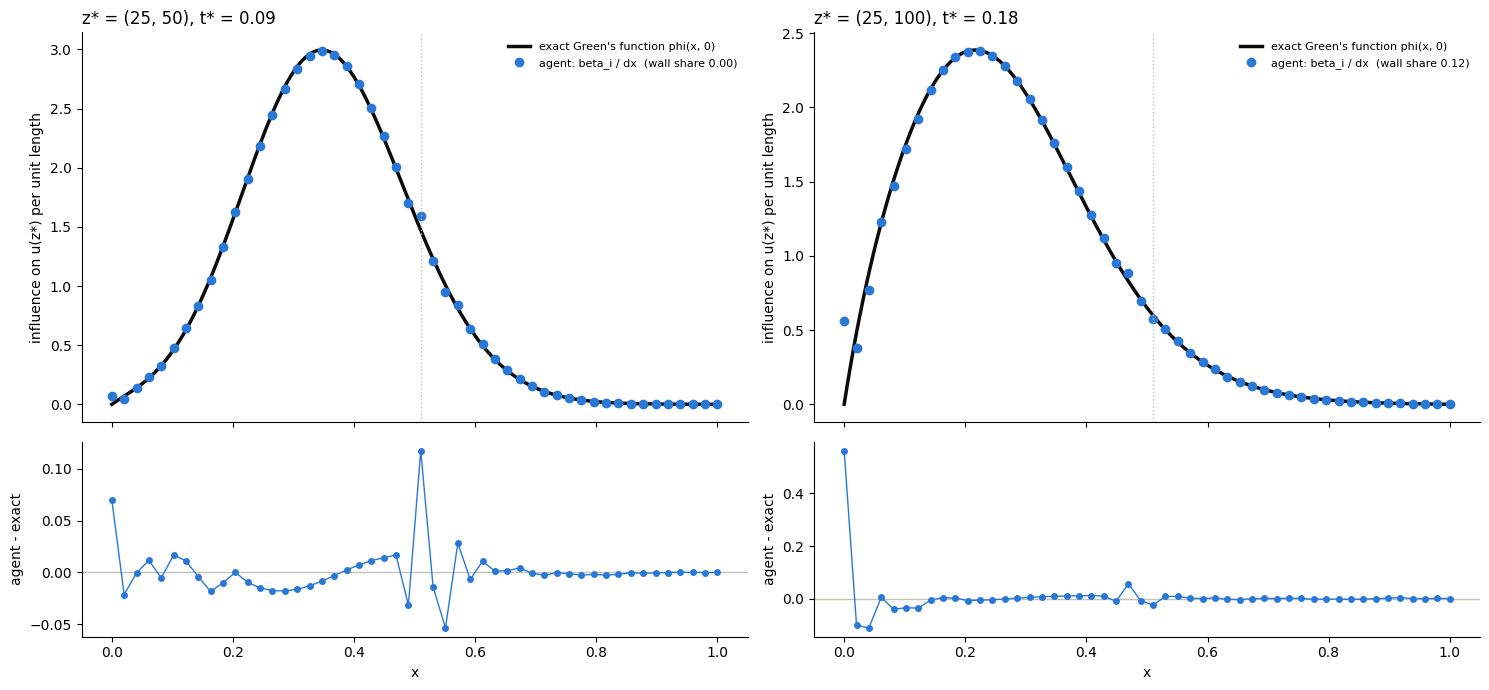

In [20]:
# ── The agent's discrete Green's function vs the exact one (adjoint of linearised Burgers), at each query ──
#   uses adjoint_ic and ic_influence from the previous cell
fig, axes = plt.subplots(2, len(Z_ADJ), figsize=(7.5 * len(Z_ADJ), 7), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
for col, z in enumerate(Z_ADJ):
    phi = adjoint_ic(z)
    ic, wall = ic_influence(run_policy(model, z, 1.0).m)
    top, bot = axes[0, col], axes[1, col]
    top.plot(xf, phi, "-", color="#0b0b0b", lw=2.5, label="exact Green's function phi(x, 0)")
    top.plot(x_grid, ic / dx, "o", color="#2a78d6", ms=6, label=f"agent: beta_i / dx  (wall share {wall:.2f})")
    top.axvline(z[0] * dx, color="#c3c2b7", ls=":", lw=1)
    top.set_title(f"z* = {z}, t* = {z[1] * dt:.2f}", loc="left")
    top.set_ylabel("influence on u(z*) per unit length"); top.legend(fontsize=8, frameon=False)
    bot.axhline(0, color="#c3c2b7", lw=1)
    bot.plot(x_grid, ic / dx - np.interp(x_grid, xf, phi), "o-", color="#2a78d6", ms=4, lw=1)
    bot.set_xlabel("x"); bot.set_ylabel("agent - exact")
    for ax in (top, bot):
        ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

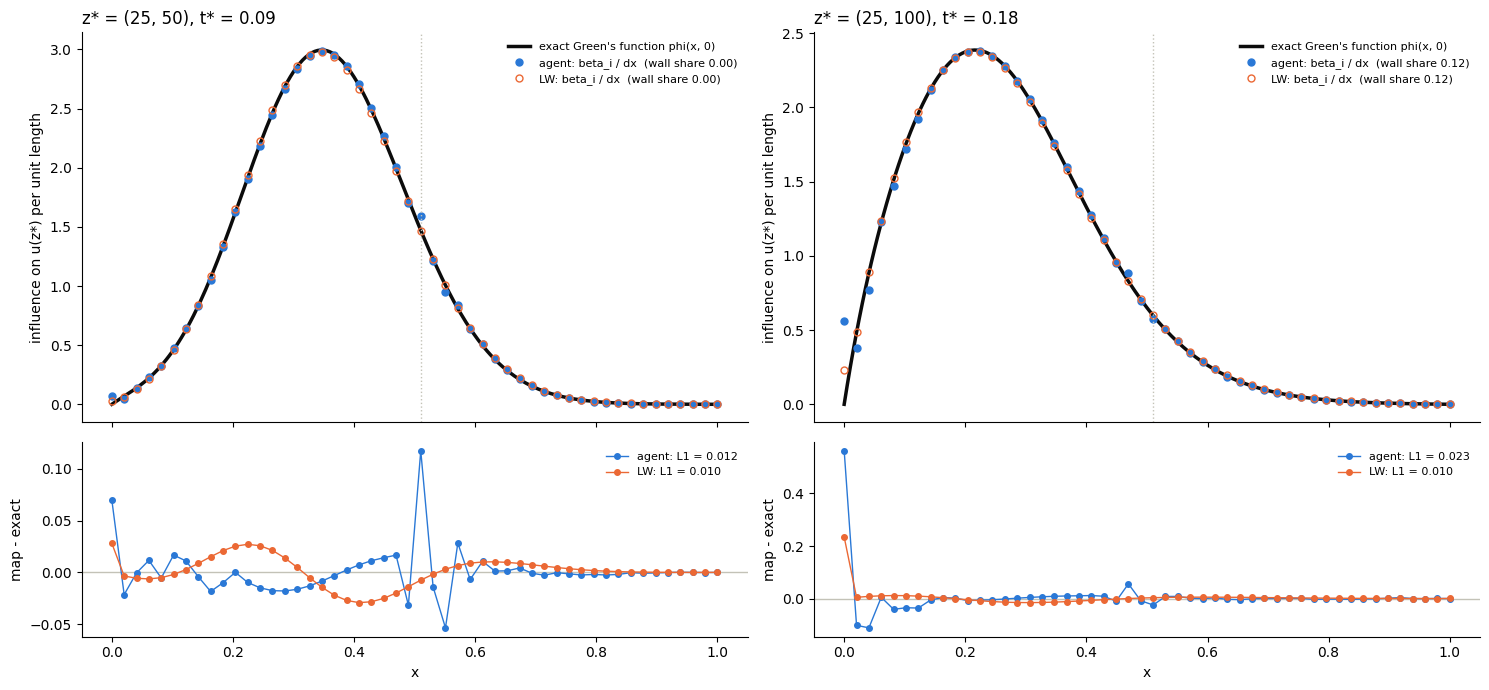

In [21]:
# ── The agent's and LW's discrete Green's functions vs the exact one, at each query ──
#   uses adjoint_ic (corrected, conservative form) and ic_influence from the earlier cell
maps_k = {"agent": lambda z: run_policy(model, z, 1.0).m, "LW": lambda z: build_map(z, lw)}
COL_K  = {"agent": "#2a78d6", "LW": "#af5d3d"}
fig, axes = plt.subplots(2, len(Z_ADJ), figsize=(7.5 * len(Z_ADJ), 7), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
for col, z in enumerate(Z_ADJ):
    phi = adjoint_ic(z)
    phi_g = np.interp(x_grid, xf, phi)
    top, bot = axes[0, col], axes[1, col]
    top.plot(xf, phi, "-", color="#0b0b0b", lw=2.5, label="exact Green's function phi(x, 0)")
    bot.axhline(0, color="#c3c2b7", lw=1)
    for name, make in maps_k.items():
        ic, wall = ic_influence(make(z))
        diff = ic / dx - phi_g
        top.plot(x_grid, ic / dx, "o", color=COL_K[name], ms=5, mfc="none" if name == "LW" else COL_K[name],
                 label=f"{name}: beta_i / dx  (wall share {wall:.2f})")
        bot.plot(x_grid, diff, "o-", color=COL_K[name], ms=4, lw=1, label=f"{name}: L1 = {np.abs(diff).sum() * dx:.3f}")
    top.axvline(z[0] * dx, color="#c3c2b7", ls=":", lw=1)
    top.set_title(f"z* = {z}, t* = {z[1] * dt:.2f}", loc="left")
    top.set_ylabel("influence on u(z*) per unit length"); top.legend(fontsize=8, frameon=False)
    bot.set_xlabel("x"); bot.set_ylabel("map - exact"); bot.legend(fontsize=8, frameon=False)
    for ax in (top, bot):
        ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

In [22]:
MULTI_DIR  = os.path.join("runs10-19", "inflow_smooth_multi15_gae0.97_lam1-1")
MULTI_CKPT = "ppo_1999992_steps"          # 2M steps; then re-run with the latest, e.g. "ppo_15999936_steps"

In [23]:
agents = {"multi": MaskablePPO.load(os.path.join(MULTI_DIR, "checkpoints", MULTI_CKPT), device="cpu"),
          "single": MaskablePPO.load(os.path.join(SINGLE_DIR, "checkpoints", "ppo_final"), device="cpu")}


(1) single's own query: 1 queries
  z* = (25, 50)   LW: 1824 pts, err 4e-04 | single: 1899 pts, err 1e-06 | multi 2M: 1894 pts, err 4e-05 | multi 16M: 1886 pts, err 2e-04

(2) multi's training queries: 14 queries
  z* = (15, 40)   LW: 1254 pts, err 6e-04 | single: 1411 pts, err 8e-05 | multi 2M: 1414 pts, err 3e-05 | multi 16M: 1116 pts, err 3e-04
  z* = (25, 40)   LW: 1344 pts, err 2e-04 | single: 1427 pts, err 1e-05 | multi 2M: 1412 pts, err 2e-05 | multi 16M: 1453 pts, err 7e-05
  z* = (35, 40)   LW: 1234 pts, err 8e-04 | single: 1446 pts, err 5e-05 | multi 2M: 1266 pts, err 8e-04 | multi 16M: 1565 pts, err 4e-04
  z* = (15, 50)   LW: 1734 pts, err 6e-04 | single: 1892 pts, err 1e-04 | multi 2M: 1858 pts, err 7e-05 | multi 16M: 1614 pts, err 3e-04
  z* = (35, 50)   LW: 1714 pts, err 8e-04 | single: 1926 pts, err 7e-05 | multi 2M: 1748 pts, err 8e-04 | multi 16M: 2037 pts, err 6e-04
  z* = (15, 60)   LW: 2214 pts, err 7e-04 | single: 2360 pts, err 1e-04 | multi 2M: 2342 pts, err 2e-

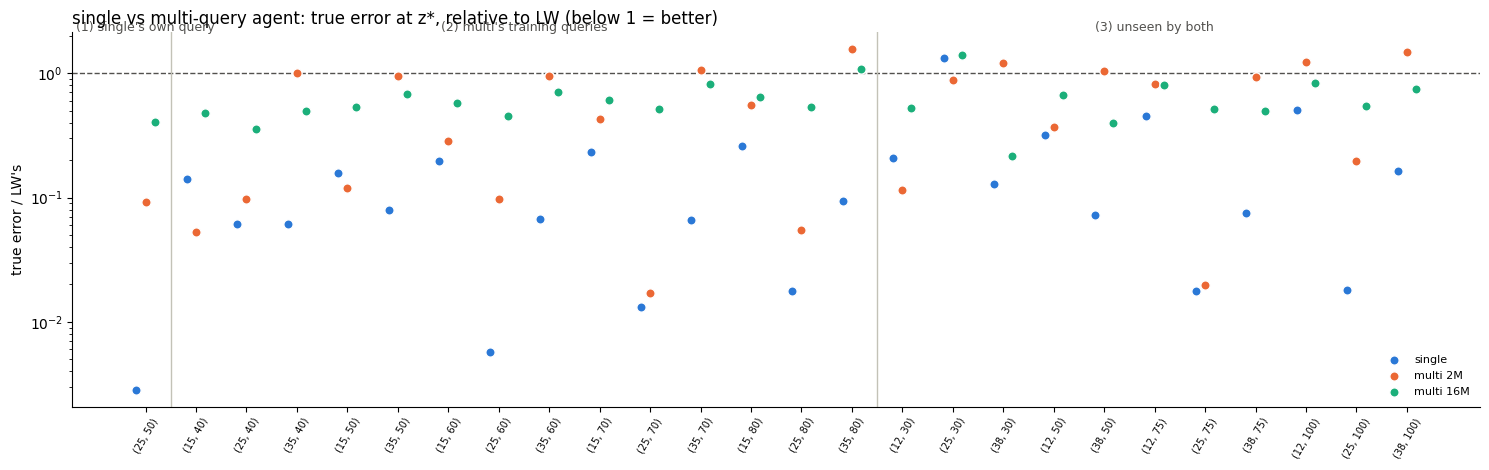

In [24]:
# ══ Single-query vs multi-query agent ══
#   Groups:  (1) the single agent's own training query    (2) the multi agent's other training queries
#            (3) queries neither agent trained on
#   Multi-query training is worth it only if multi is close to single in (1) and better in (2) and (3).
#   Several multi checkpoints are compared (the run peaked early). Live-speed forward pass; u_true ONLY for reporting.
MULTI_DIR  = os.path.join("runs10-19", "inflow_smooth_multi15_gae0.97_lam1-1")
SINGLE_DIR = os.path.join("runs10-15", "inflow_smooth_scratch_gae0.97_z25-50_lam1-1")
ckpts  = sorted((f[:-4] for f in os.listdir(os.path.join(MULTI_DIR, "checkpoints")) if f.endswith("_steps.zip")),
                key=lambda f: int(f.split("_")[1]))
MULTI_CKPTS = [ckpts[0], ckpts[-1]]                     # 2M steps and the latest; add others from `ckpts` if wanted
cfg_m, cfg_s = [json.load(open(os.path.join(d, "config.json"))) for d in (MULTI_DIR, SINGLE_DIR)]
assert cfg_m["problem"] == cfg_s["problem"] == PROBLEM, f"problems differ: {cfg_m['problem']}, {cfg_s['problem']}, {PROBLEM}"
TRAIN_M, TRAIN_S = [tuple(q) for q in cfg_m["queries"]], [tuple(q) for q in cfg_s["queries"]]
LAM = 1.0
GROUPS = {"(1) single's own query": TRAIN_S,
          "(2) multi's training queries": [z for z in TRAIN_M if z not in TRAIN_S],
          "(3) unseen by both": [z for z in [(ix, it) for it in (30, 50, 75, 100) for ix in (12, 25, 38)] if z not in TRAIN_M + TRAIN_S]}
agents = {"single": MaskablePPO.load(os.path.join(SINGLE_DIR, "checkpoints", "ppo_final"), device="cpu")}
for c in MULTI_CKPTS:
    agents[f"multi {int(c.split('_')[1]) / 1e6:.0f}M"] = MaskablePPO.load(os.path.join(MULTI_DIR, "checkpoints", c), device="cpu")
NAMES = ["LW"] + list(agents)

# ── every query: LW and all agents ──
res = {}
for group, zs in GROUPS.items():
    print(f"\n{group}: {len(zs)} queries")
    for z in zs:
        res[z] = {"LW": report(build_map(z, lw)), **{n: report(run_policy(a_, z, LAM).m) for n, a_ in agents.items()}}
        print(f"  z* = {str(z):10s} " + " | ".join(f"{n}: {res[z][n]['points']} pts, err {res[z][n]['error']:.0e}" for n in NAMES))

# ── summary: each agent relative to LW, and each multi checkpoint relative to single (medians over the group) ──
med = lambda zs, a_, b, k: np.median([res[z][a_][k] / res[z][b][k] for z in zs])
print(f"\n{'group':32s} {'agent':>11s} | {'/ LW: points':>12s} {'bound':>7s} {'error':>7s} | {'/ single: bound':>15s} {'error':>7s} {'wins':>6s}")
for group, zs in GROUPS.items():
    for n in agents:
        rel_single = (f"{med(zs, n, 'single', 'bound'):15.2f} {med(zs, n, 'single', 'error'):7.2f} "
                      f"{sum(res[z][n]['error'] < res[z]['single']['error'] for z in zs):3d}/{len(zs)}") if n != "single" else ""
        print(f"{group:32s} {n:>11s} | {med(zs, n, 'LW', 'points'):12.2f} {med(zs, n, 'LW', 'bound'):7.2f} "
              f"{med(zs, n, 'LW', 'error'):7.2f} | {rel_single}")
print("\n/ LW and / single < 1 = better; wins = queries where that multi checkpoint has a lower true error than single")

# ── figure: true error relative to LW, every query, grouped ──
COL_A = {n: c for n, c in zip(agents, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"])}
zs_all = [z for zs in GROUPS.values() for z in zs]
fig, ax = plt.subplots(figsize=(15, 4.8))
for j, n in enumerate(agents):
    ax.scatter(np.arange(len(zs_all)) + (j - (len(agents) - 1) / 2) * 0.18, [res[z][n]["error"] / res[z]["LW"]["error"] for z in zs_all],
               s=45, color=COL_A[n], edgecolor="white", linewidth=1, label=n, zorder=3)
ax.axhline(1, color="#52514e", lw=1, ls="--")
start = 0
for group, zs in GROUPS.items():                                     # group separators and labels
    ax.text(start + (len(zs) - 1) / 2, 2.2, group, ha="center", fontsize=9, color="#52514e")
    start += len(zs)
    if start < len(zs_all):
        ax.axvline(start - 0.5, color="#c3c2b7", lw=1)
ax.set_yscale("log"); ax.set_xticks(range(len(zs_all))); ax.set_xticklabels([str(z) for z in zs_all], rotation=60, fontsize=7)
ax.set_ylabel("true error / LW's"); ax.set_title("single vs multi-query agent: true error at z*, relative to LW (below 1 = better)", loc="left")
ax.spines[["top", "right"]].set_visible(False); ax.legend(fontsize=8, frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

### Error vs points: 3 seeds vs second-order schemes
FD-3, LW, CN refined 1–4× (curves) vs each seed's agent (stars); "points to match" = points a scheme needs to reach the agent's error (* = extrapolated).


z* = (25, 50)  (training query): points to match each seed's error
             agent pts    error |         FD-3 |           LW |           CN
  seed 1          2004  1.1e-06 |  223034748* (111295x) |   44742902* (22327x) |     101255* (  51x)
  seed 2          2215  9.7e-05 |     229206* ( 103x) |      45525  (  21x) |      26655  (  12x)
  seed 4          1968  1.0e-04 |     206128* ( 105x) |      40885  (  21x) |       4818  (   2x)

z* = (38, 75)  (unseen): points to match each seed's error
             agent pts    error |         FD-3 |           LW |           CN
  seed 1          3235  8.4e-05 |     510271* ( 158x) |     100155  (  31x) |      15812  (   5x)
  seed 2          3356  8.9e-05 |     467080* ( 139x) |      91665  (  27x) |      15536  (   5x)
  seed 4          3101  2.3e-04 |     112310  (  36x) |      21464  (   7x) |       1648  (   1x)

z* = (25, 100)  (unseen): points to match each seed's error
             agent pts    error |         FD-3 |           LW |   

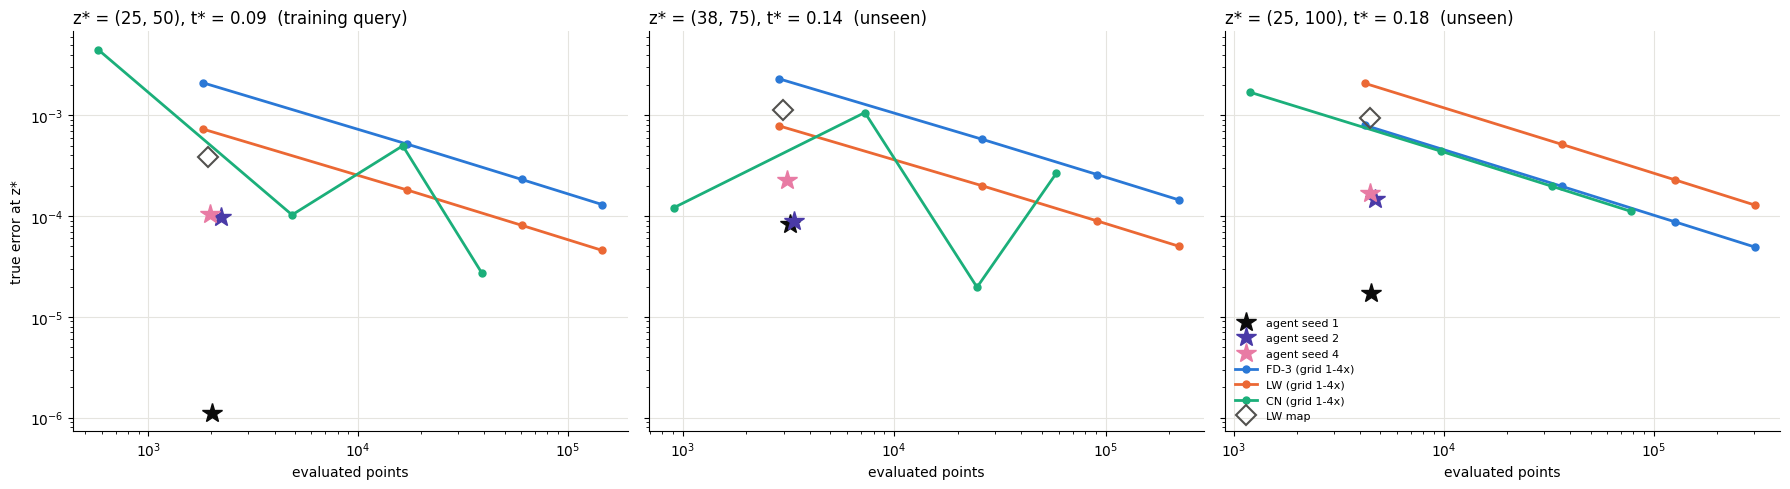

In [34]:
# ══ The 3 seeds against the second-order schemes: true error at z* vs evaluated points ══
#   Second-order schemes (FD-3, LW, CN) on grids refined 1-4x give a curve each; each seed's agent is one point.
#   "points to match": how many points each scheme needs to reach the agent's error, read off its curve
#   (log-log interpolation; beyond its finest grid, extrapolated with the slope of its last two points, marked *).
#   Needs classical() from the classical-solver cell above. u_true ONLY for reporting.
a = lambda u: u                    # the Burgers speed a(u) = u (restore it: an earlier cell reused the name `a`)
SEED_DIRS = {1: os.path.join("runs10-15", "inflow_smooth_scratch_gae0.97_z25-50_lam1-1"),
             2: os.path.join("runs10-20", "inflow_smooth_scratch_gae0.97_z25-50_lam1-1_seed2"),
             4: os.path.join("runs10-20", "inflow_smooth_scratch_gae0.97_z25-50_lam1-1_seed4")}
seed_models = {s: MaskablePPO.load(os.path.join(d, "checkpoints", "ppo_final"), device="cpu") for s, d in SEED_DIRS.items()}
SCHEMES2 = ["FD-3", "LW", "CN"]
Z_PTS = [(25, 50), (38, 75), (25, 100)]                           # the training query and two unseen ones

def points_to_match(curve, err):
    """Points a scheme needs for error err, from its (points, error) curve: (points, extrapolated?)."""
    P, E = np.log(curve[:, 0]), np.log(curve[:, 1])
    if err >= curve[:, 1].max():
        return curve[np.argmax(curve[:, 1]), 0], False
    for i in range(len(P) - 1):
        if min(E[i], E[i + 1]) <= np.log(err) <= max(E[i], E[i + 1]):
            f = (np.log(err) - E[i]) / (E[i + 1] - E[i])
            return float(np.exp(P[i] + f * (P[i + 1] - P[i]))), False
    slope = (E[-1] - E[-2]) / (P[-1] - P[-2])                     # beyond the finest grid
    return float(np.exp(P[-1] + (np.log(err) - E[-1]) / slope)), True

COL2 = {"FD-3": "#2a78d6", "LW": "#eb6834", "CN": "#1baf7a"}
SEED_COL = {1: "#0b0b0b", 2: "#4a3aa7", 4: "#e87ba4"}
fig, axes = plt.subplots(1, len(Z_PTS), figsize=(6 * len(Z_PTS), 5), sharey=True)
for ax, z in zip(axes, Z_PTS):
    curves = {s: np.array(sorted(classical(s, k, z) for k in (1, 2, 3, 4))) for s in SCHEMES2}
    guess_cost = (len(xc) - 2) * int(np.ceil(z[1] * dt / tau))
    print(f"\nz* = {z}{'  (training query)' if z == (25, 50) else '  (unseen)'}: points to match each seed's error")
    print(f"  {'':10s} {'agent pts':>9s} {'error':>8s} | " + " | ".join(f"{s:>12s}" for s in SCHEMES2))
    for s, mdl in seed_models.items():
        rep = report(run_policy(mdl, z, 1.0).m)
        pts = rep["points"] + guess_cost
        cells = []
        for sc_ in SCHEMES2:
            n, ext = points_to_match(curves[sc_], rep["error"])
            cells.append(f"{n:10.0f}{'*' if ext else ' '} ({n / pts:4.0f}x)")
        print(f"  seed {s:<5d} {pts:9d} {rep['error']:8.1e} | " + " | ".join(cells))
        ax.loglog(pts, rep["error"], "*", color=SEED_COL[s], ms=15, label=f"agent seed {s}")
    for sc_ in SCHEMES2:
        ax.loglog(curves[sc_][:, 0], curves[sc_][:, 1], "o-", color=COL2[sc_], lw=2, ms=5, label=f"{sc_} (grid 1-4x)")
    r_lw = report(build_map(z, lw))
    ax.loglog(r_lw["points"] + guess_cost, r_lw["error"], "D", color="#52514e", mfc="none", ms=10, mew=1.5, label="LW map")
    ax.set_title(f"z* = {z}, t* = {z[1] * dt:.2f}" + ("  (training query)" if z == (25, 50) else "  (unseen)"), loc="left")
    ax.set_xlabel("evaluated points"); ax.grid(True, which="major", color="#e5e4df", lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("true error at z*"); axes[-1].legend(fontsize=8, frameon=False, loc="lower left")
plt.tight_layout(); plt.show()

### Stencils used by each seed
Map at (25, 50) coloured by stencil, the 6 most used per seed, and whether the seeds share their top stencil.

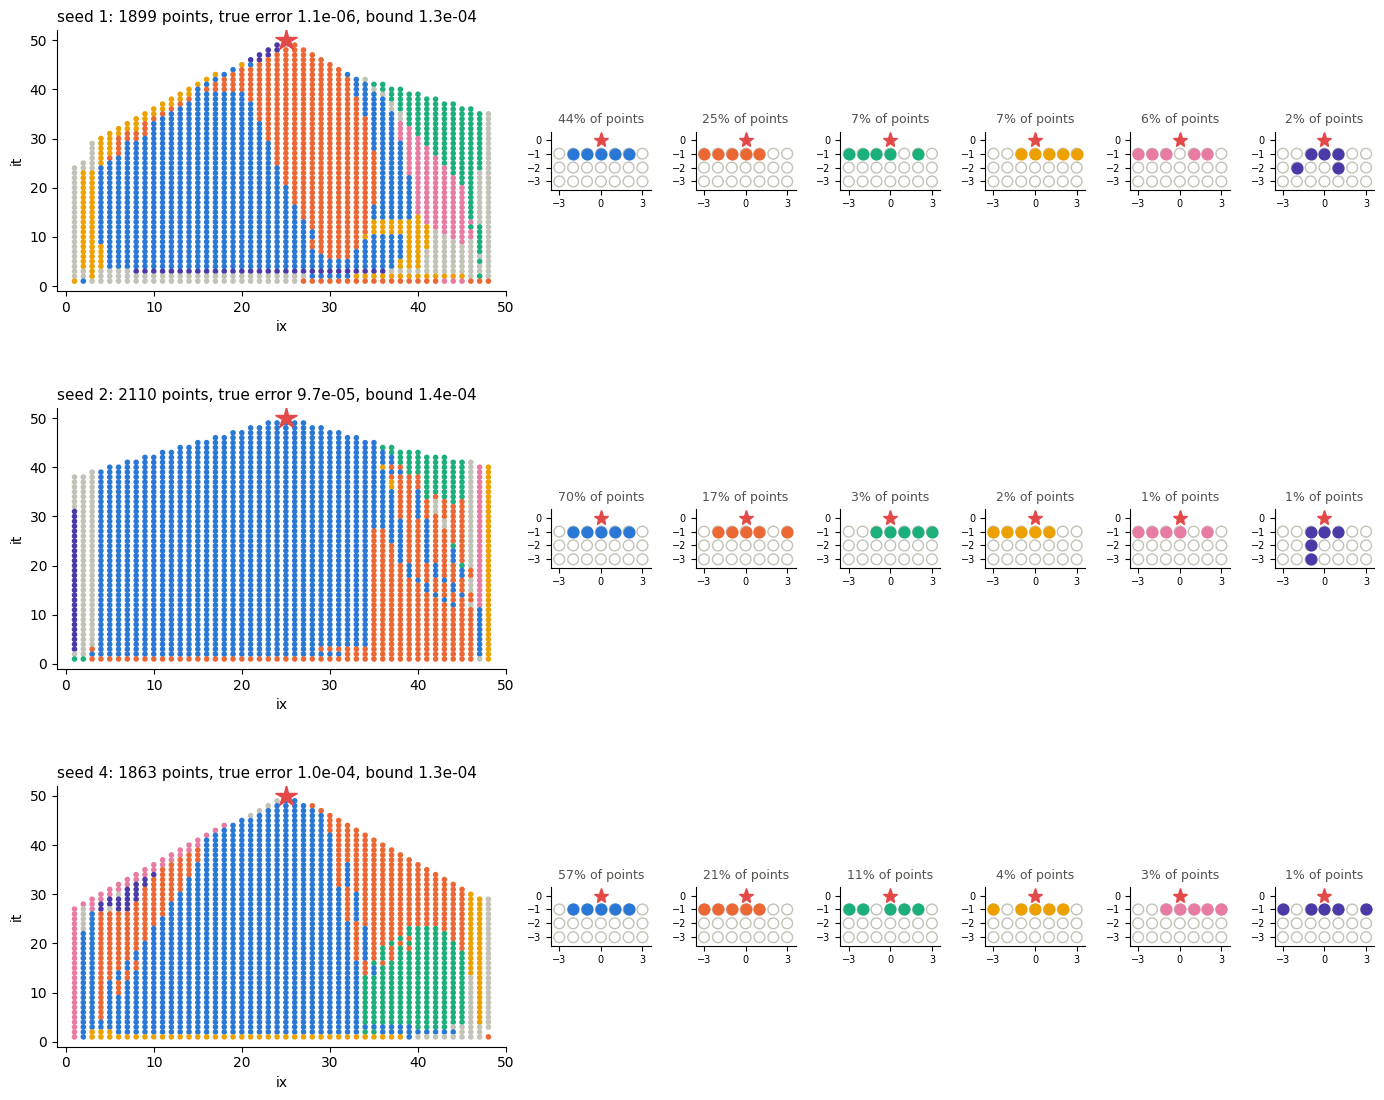

seed 1: top 3 = [(-2, -1), (-1, -1), (0, -1), (1, -1), (2, -1)] | [(-3, -1), (-2, -1), (-1, -1), (0, -1), (1, -1)] | [(-3, -1), (-2, -1), (-1, -1), (0, -1), (2, -1)]
seed 2: top 3 = [(-2, -1), (-1, -1), (0, -1), (1, -1), (2, -1)] | [(-2, -1), (-1, -1), (0, -1), (1, -1), (3, -1)] | [(-1, -1), (0, -1), (1, -1), (2, -1), (3, -1)]
seed 4: top 3 = [(-2, -1), (-1, -1), (0, -1), (1, -1), (2, -1)] | [(-3, -1), (-2, -1), (-1, -1), (0, -1), (1, -1)] | [(-3, -1), (-2, -1), (0, -1), (1, -1), (2, -1)]
top stencil shared by all seeds: True


In [35]:
# ── Which stencils each seed uses, and where: one row per seed, map at the training query coloured by stencil ──
Z_SHOW = (25, 50)
TOP_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"]
def stencil_cells(p, nbs):
    offs = [(q[0] - p[0], q[1] - p[1]) for q in nbs]
    return tuple(sorted(WINDOW.index(o) for o in offs)) if all(o in WINDOW for o in offs) else None

fig = plt.figure(figsize=(17, 4.4 * len(seed_models)))
gs = fig.add_gridspec(len(seed_models), 7, width_ratios=[4.5, 1, 1, 1, 1, 1, 1], hspace=0.45, wspace=0.3)
tops = {}
for row, (s, mdl) in enumerate(seed_models.items()):
    m = run_policy(mdl, Z_SHOW, 1.0).m
    cells = {p: stencil_cells(p, nbs) for p, (nbs, w) in m["stencil"].items()}
    count = Counter(c for c in cells.values() if c is not None)
    top6 = [c for c, _ in count.most_common(6)]
    tops[s] = top6
    color = {c: TOP_COLORS[i] for i, c in enumerate(top6)}
    rep = report(m)
    ax = fig.add_subplot(gs[row, 0])
    P = np.array(list(cells))
    ax.scatter(P[:, 0], P[:, 1], s=9, c=["#e5e4df" if c is None else color.get(c, "#c3c2b7") for c in cells.values()])
    ax.plot(*Z_SHOW, "*", color="#e34948", ms=16)
    ax.set_xlim(-1, nx); ax.set_ylim(-1, Z_SHOW[1] + 2); ax.set_xlabel("ix"); ax.set_ylabel("it")
    ax.set_title(f"seed {s}: {rep['points']} points, true error {rep['error']:.1e}, bound {rep['bound']:.1e}", loc="left", fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)
    total = sum(count.values())
    for i, c in enumerate(top6):
        g = fig.add_subplot(gs[row, i + 1])
        g.scatter(*np.array(WINDOW).T, s=60, facecolors="none", edgecolors="#c3c2b7")
        g.scatter(*np.array([WINDOW[k] for k in c]).T, s=60, color=TOP_COLORS[i])
        g.plot(0, 0, "*", color="#e34948", ms=11)
        g.set_xlim(-3.6, 3.6); g.set_ylim(-3.6, 0.6); g.set_aspect("equal")
        g.set_xticks([-3, 0, 3]); g.set_yticks([0, -1, -2, -3]); g.tick_params(labelsize=7)
        g.set_title(f"{count[c] / total:.0%} of points", fontsize=9, color="#52514e"); g.spines[["top", "right"]].set_visible(False)
plt.show()

# ── do the seeds agree on their stencils? ──
for s, t in tops.items():
    print(f"seed {s}: top 3 = " + " | ".join(str([WINDOW[k] for k in c]) for c in t[:3]))
print("top stencil shared by all seeds:", len({t[0] for t in tops.values()}) == 1)

In [36]:
# ══ Is depth worth it? The best UNIFORM scheme using only cells 1, 2 or 3 levels down (rules only, no training) ══
#   depth k: the stencil may only use window cells at least k levels below p, so a uniform depth-k scheme skips k-1 levels
#   (about 1/k of the points). Candidates: the 60 lowest-score stencils at the training query among those allowed;
#   the one with the smallest exact bound there is kept (exact error used ONLY to pick this baseline). u_true for reporting.
def best_uniform(depth, n_cand=60):
    sets, _, sc = admissible(Z_TRAIN)
    ok = [i for i, s_ in enumerate(sets) if all(WINDOW[k][1] <= -depth for k in s_)]
    cand = [sets[i] for i in sorted(ok, key=lambda i: sc[i])[:n_cand]]
    return min(cand, key=lambda s_: report(build_map(Z_TRAIN, fixed_rule(s_)))["bound"]), len(ok)

rules_d = {"LW": lw, "agent": None}
for depth in (1, 2, 3):
    s_, n_ok = best_uniform(depth)
    rules_d[f"depth {depth}"] = fixed_rule(s_)
    print(f"depth {depth}: best of {min(60, n_ok)} candidates ({n_ok} admissible): {[WINDOW[k] for k in s_]}")

Z_DEPTH = [Z_TRAIN, (12, 100), (25, 150), (38, 150)]
print(f"\n{'z*':>10s} | " + " | ".join(f"{n:>21s}" for n in rules_d) + "   (points, true error)")
for z in Z_DEPTH:
    row = {n: report(run_policy(model, z, LAM).m if r is None else build_map(z, r)) for n, r in rules_d.items()}
    print(f"{str(z):>10s} | " + " | ".join(f"{row[n]['points']:6d} pts {row[n]['error']:.1e}" for n in rules_d)
          + ("  (train)" if z == Z_TRAIN else ""))

depth 1: best of 60 candidates (18768 admissible): [(-2, -2), (-1, -2), (1, -2), (2, -2), (3, -2)]
depth 2: best of 60 candidates (1881 admissible): [(-2, -2), (-1, -2), (1, -2), (2, -2), (3, -2)]
depth 3: best of 21 candidates (21 admissible): [(-3, -3), (-2, -3), (0, -3), (1, -3), (2, -3)]

        z* |                    LW |                 agent |               depth 1 |               depth 2 |               depth 3   (points, true error)
  (25, 50) |   1824 pts 3.9e-04 |   1899 pts 1.1e-06 |   1451 pts 9.8e-05 |   1451 pts 9.8e-05 |    818 pts 1.7e-04  (train)
 (12, 100) |   4068 pts 4.8e-04 |   4168 pts 2.4e-04 |   4008 pts 1.7e-04 |   4008 pts 1.7e-04 |   3146 pts 4.8e-04
 (25, 150) |   6624 pts 9.1e-04 |   6729 pts 2.8e-05 |   6282 pts 3.0e-04 |   6282 pts 3.0e-04 |   5578 pts 8.1e-04
 (38, 150) |   6442 pts 7.5e-04 |   6623 pts 9.9e-05 |   6181 pts 2.0e-04 |   6181 pts 2.0e-04 |   5824 pts 5.8e-04
